In [1]:
import random as r
import numpy as np
import matplotlib.pyplot as plt

<h3> Generowanie losowych liczb

In [2]:
r.uniform(-5, 5) #losowa liczba z rozkladu UNIF[-5,5]

-3.6068252794773867

In [3]:
r.gauss(2, 3) #losowa liczba z rozkladu N(2,3)

6.059874303300536

In [4]:
x = [3,4,5]
r.choice(x) #losowy element z listy

3

<h3> Sekwencje biologiczne 

In [5]:
#Model1. Pozycje są niezależne
def random_seq(length, dist):
    '''Funkcja zwraca losową sekwencje o zadanej dlugosci i zadanej czestosci liter alfabetu'''
    distT = []
    h = 0
    for (k, v) in dist.items():
        h += v
        distT.append((k,h))
    s = ''
    for x in range(length):
        ran = r.random()
        for k,v in distT:
            if ran <= v:
                s+=k
                break
    return s

##############przyklad
dist = {'A':0, 'C':1/3,'G':1/3,'T':1/3}
seq = random_seq(10, dist) #podajemy długość sekwencji, tutaj 10
##############
print(seq)

TCTTGCGGCG


In [6]:
#Model2. Bieżący nukleotyd jest zależny od wcześniejszego (model Markowa rzędu 1):
def random_seq2(length, nuc, firstN, trans):
    '''Funkcja zwraca losowa sekwencje o zadanej dlugosci i zadanej macierzy przejsc'''
    s_losowa = ''
    for i in range(length):
        if i>0:
            s_losowa+=np.random.choice(nuc, 1, p=trans[s_losowa[-1]])[0]
        else:
            s_losowa+=np.random.choice(nuc, 1, p=firstN)[0]
    return s_losowa

nuc = ["A","C","G","T"]
trans = {} #macierz przejsc (mozemy zablokowac lub wzmocnić pewne przejścia, w przykladzie ponizej nie będzie sekwencji CA)

####################przyklad
#              "A",  "C",  "G",  "T"
trans['A'] = [0.25, 0.25, 0.25, 0.25]
trans['C'] = [0,    1/3,   1/3, 1/3]
trans['G'] = [0.25, 0.25, 0.25, 0.25]
trans['T'] = [0.25, 0.25, 0.25, 0.25]

firstN = [0.25, 0.25, 0.25, 0.25] #pierwszy nukleotyd będzie zupelnie losowy
seq = random_seq2(100, nuc, firstN, trans)  #podajemy dlugosc sekwencji, tutaj 100
#####################
print(seq)

ATGTTCTCCTTGACTAGAGATCCTTGTCGAACTGCCTGCCGTTTTCCTGGCCCCTGCGGGGTGTCTCTCTTATCCGGTTCGGCGTTGTCCTCTTCCTATA


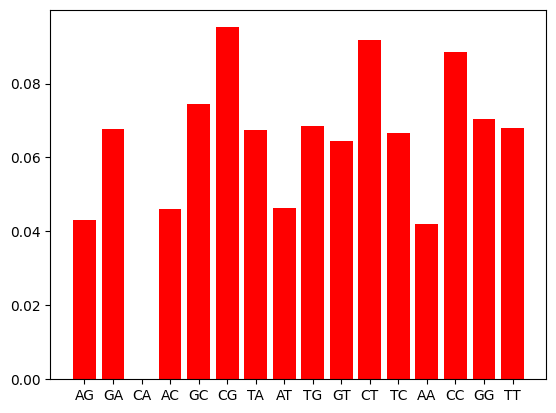

In [7]:
#Wyznaczanie częstosci dinukleotydów dla zadanej sekwencji 
################################
seq = random_seq2(10000, nuc, firstN, trans)
################################


diplets = {'AG':0, 'GA':0, 'CA':0, 'AC':0, 'GC':0, 'CG':0, 'TA':0,'AT':0,'TG':0, 'GT':0,'CT':0,'TC':0, 'AA':0, 'CC':0, 'GG':0, 'TT':0}

n = len(seq)-1
for i in range(n):
    diplets[seq[i:(i+2)]]+=1


sumD = sum(diplets.values())
norD = {k:v/sumD for k,v in diplets.items()}

height_norD = norD.values()
bars = norD.keys()
y_pos = np.arange(len(bars))
plt.bar(y_pos, height_norD,color="red")
plt.xticks(y_pos, bars)
plt.show()

Zauważ, że brak CA wpłynął też na inne dinukleotydy.

<h4> Ćwiczenie (we własnym zakresie)

- Pobierz sekwencję neuraminidazy wirusa grypy https://www.ncbi.nlm.nih.gov/nuccore/J02156.1.
  
- Wyznacz macierz prawdopodobieństw przejść $X->Y$, gdzie $X, Y \in \lbrace A, C, T, G \rbrace$.

<h4> Ćwiczenie (we własnym zakresie)

- Z NCBI pobierz sekwencję wybranego genu w którym występują introny oraz eksony.

- Wyznacz macierz prawdopodobieństw przejść $X->Y$ osobno dla intronów i eksonów.

- Porównaj otrzymane macierze. Z czego mogą wynikać ewentualne różnice?

Zastosowania
- analiza motywów sekwencyjnych
- porównywanie sekwencji
- szukanie/przewidywanie eksonów/intronów

<h3> Rozkład Pareto

In [30]:
place = [38185.61, 36010.9, 37550.76, 6116.97, 5177.8, 16813.11, 16205.46, 71038.62, 5146.01, 11846.98, 5106.87, 12288.68, 21378.56, 6708.63, 13895.66, 5487.26, 5200.79, 6306.44, 10451.66, 6861.23, 14086.23, 5827.59, 23437.15, 13841.87, 8458.79, 6885.53, 7104.0, 5136.19, 5610.95, 8676.85, 6718.97, 14291.98, 8851.91, 5900.15, 7151.74, 8355.59, 6464.16, 6343.15, 10252.79, 6208.1, 15174.38, 15940.86, 12236.45, 5118.29, 12775.25, 15446.74, 12643.47, 6118.32, 6337.82, 5544.14, 6523.11, 4894.39, 5551.89, 14932.42, 150578.21, 7812.1, 6139.4, 6771.74, 6562.47, 5374.25, 12228.46, 15735.85, 17631.74, 467477.07, 29546.09, 19843.03, 11815.67, 8009.77, 4993.75, 10962.96, 8211.54, 17634.05, 27609.02, 6398.93, 5016.61, 10666.69, 43427.32, 9754.08, 30171.11, 9198.27, 14918.75, 6164.56, 5396.45, 5434.1, 5319.16, 5037.94, 21108.73, 7075.25, 6704.22, 10760.31, 5648.01, 25117.52, 14637.99, 6383.36, 5713.26, 7596.14, 6250.43, 5130.26, 7418.44, 33486.41, 11468.03, 68519.35, 28051.19, 12598.34, 23693.73, 8993.75, 12066.4, 6670.13, 5804.91, 30536.78, 5423.9, 5651.08, 6279.65, 11066.43, 6866.28, 8670.59, 30930.52, 18154.79, 13191.34, 5569.11, 13399.64, 7111.1, 5347.12, 6781.5, 5107.4, 10577.53, 11106.36, 6193.94, 4999.73, 50537.67, 9643.11, 17334.29, 6514.29, 20389.87, 19781.64, 5207.77, 519190.06, 8589.59, 16035.89, 5929.56, 11223.24, 6151.07, 19321.08, 7164.0, 9407.44, 7576.86, 9202.2, 7221.2, 8152.37, 4926.48, 18885.74, 41819.18, 7930.31, 90416.33, 5555.38, 53006.97, 6579.53, 8553.11, 39280.27, 5361.71, 5666.14, 15290.28, 11209.3, 6160.23, 7043.26, 9173.22, 24719.32, 6545.4, 9294.32, 6522.11, 6247.67, 30238.79, 7765.4, 15249.43, 6238.97, 5642.01, 12867.43, 16310.48, 10909.07, 13375.76, 11567.35, 12319.78, 33567.46, 54810.96, 8506.77, 5197.06, 16118.71, 9967.63, 39398.02, 11825.68, 5423.75, 11874.04, 7872.31, 5307.5, 6085.71, 96202.08, 6802.0, 6003.59, 7047.8, 28561.71, 12286.7, 5699.06, 4839.8, 7010.94, 5472.39, 28564.37, 5268.53, 8668.79, 11554.14, 57054.54, 6173.57, 21460.78, 9283.15, 21354.48, 6544.32, 6402.8, 5976.13, 11819.8, 8413.93, 10139.97, 14523.26, 12997.53, 11834.09, 16049.57, 4950.81, 17588.18, 14745.08, 7014.81, 5909.3, 8868.13, 27554.19, 6365.15, 16534.67, 62140.49, 6777.98, 196203.32, 5062.86, 4962.56, 23831.15, 8383.24, 8103.68, 26018.58, 40588.53, 9781.08, 29543.42, 11484.06, 7405.04, 5927.49, 15748.29, 30430.78, 48013.96, 6235.25, 11636.83, 7481.01, 21024.02, 5813.23, 5056.53, 6560.05, 5107.85, 7213.75, 7318.84, 5299.51, 68804.6, 6236.17, 13484.78, 5713.89, 7451.81, 5194.82, 5319.89, 4852.42, 19344.79, 6528.12, 8731.72, 10165.07, 5611.83, 60246.24, 7699.15, 5128.66, 5275.15, 7372.37, 5362.02, 6367.34, 9121.83, 4981.04, 6548.64, 18601.03, 5124.88, 11093.74, 5019.72, 48355.48, 5983.46, 5936.64, 12300.16, 33703.28, 75031.96, 15815.78, 21310.19, 12371.83, 5673.72, 13127.88, 5549.61, 11275.04, 9311.91, 6541.13, 8864.53, 10461.17, 5868.63, 6891.45, 6919.1, 5295.11, 6169.14, 11639.46, 13465.35, 7882.39, 8061.14, 6772.34, 13138.82, 6821.47, 10977.77, 8345.19, 8063.51, 57214.64, 30535.1, 10937.9, 13439.95, 5459.87, 7166.64, 14774.13, 11608.89, 5893.97, 69917.53, 4967.67, 12549.26, 5222.58, 39973.88, 5178.43, 18311.02, 5617.94, 240835.94, 7910.69, 13225.96, 11180.44, 8562.21, 16659.73, 9095.75, 51032.04, 5065.69, 487639.67, 9811.16, 6196.82, 7968.71, 14033.68, 11349.69, 29062.24, 34182.32, 10858.97, 18672.17, 8579.08, 5306.95, 7680.87, 6192.42, 26304.8, 5854.41, 14414.36, 34096.24, 5393.86, 10894.7, 45536.41, 7498.37, 7345.89, 8519.14, 5739.68, 5613.14, 69990.38, 38079.48, 7984.42, 6351.78, 15311.79, 203985.74, 31131.51, 7307.51, 8505.93, 12357.63, 9180.91, 6354.95, 6339.0, 12226.07, 97619.53, 5669.5, 13397.25, 46178.85, 4859.07, 7712.58, 15361.74, 34113.87, 54524.7, 6409.65, 5107.53, 6450.49, 9652.52, 6038.31, 6959.04, 16331.82, 4879.36, 22228.27, 4894.41, 10971.9, 5057.0, 6332.98, 7951.87, 31347.04, 5788.77, 136974.0, 31425.31, 5145.65, 4843.16, 5563.52, 11134.78, 980492.0, 6527.79, 16034.38, 5166.4, 18465.56, 26676.64, 32494.66, 33455.2, 19853.78, 5170.46, 9779.48, 7000.76, 7197.38, 32963.29, 30806.33, 13170.29, 5969.9, 12431.64, 6157.37, 17281.59, 5678.23, 13334.45, 7239.71, 5213.87, 15793.33, 5361.78, 191235.49, 8481.16, 6527.36, 5707.6, 9013.47, 15944.3, 22221.7, 10253.91, 89144.71, 18310.13, 5605.18, 78227.13, 6807.38, 90096.65, 6279.59, 7562.38, 12909.38, 5121.18, 46552.23, 7075.29, 6009.77, 5064.21, 4912.7, 4928.31, 6676.43, 6583.97, 11584.42, 34605.59, 13206.45, 12303.9, 7747.06, 11071.41, 9583.65, 5033.68, 6058.85, 6009.67, 5135.22, 7129.19, 5058.14, 17578.54, 18124.22, 5273.74, 5176.62, 71372.36, 6298.45, 8821.79, 8164.53, 14403.64, 11745.14, 34560.29, 5654.07, 11705.31, 6961.16, 8900.35, 171181.74, 7662.78, 13280.44, 8345.75, 5692.83, 4888.05, 18438.95, 5218.99, 5691.91, 10558.97, 6631.18, 8144.74, 8242.34, 4907.15, 32203.02, 158599.95, 8671.19, 6861.67, 34035.31, 7629.87, 11123.34, 28598.84, 6967.19, 25279.9, 12877.32, 11642.97, 22019.31, 4866.95, 6630.59, 5837.51, 6380.04, 6916.04, 6000.23, 8035.55, 6515.17, 7794.64, 8422.67, 6071.03, 11092.3, 13243.42, 18406.9, 5858.29, 11302.66, 15683.32, 5007.58, 7857.78, 10907.01, 6211.73, 23447.24, 14679.0, 5660.11, 8039.28, 86515.48, 9561.08, 16373.42, 40548.5, 8012.37, 5225.44, 5952.03, 8514.04, 7970.35, 9671.5, 14979.18, 17823.0, 12049.54, 56581.89, 108455.6, 14804.59, 25739.19, 7492.83, 5442.32, 9928.86, 44830.59, 5516.87, 7011.22, 11362.95, 7884.97, 5033.21, 172768.18, 9391.12, 6182.38, 7381.33, 4929.64, 9620.55, 19859.99, 9637.0, 17287.76, 8603.71, 16873.47, 8840.6, 11603.31, 25209.0, 211889.17, 7642.44, 93677.7, 5293.38, 10517.82, 8806.5, 10112.1, 23620.41, 7356.55, 179790.18, 9529.4, 16948.06, 10346.1, 9072.86, 7891.8, 4908.06, 142147.05, 11797.77, 51890.34, 156963.08, 18272.34, 7264.15, 8302.75, 5237.2, 37085.22, 13240.0, 51340.44, 38812.41, 4979.12, 22005.13, 5450.46, 5133.31, 12801.76, 8121.79, 18692.15, 80601.39, 7722.72, 10656.94, 4818.97, 5865.78, 12635.17, 4858.07, 11861.27, 11308.97, 5226.56, 45211.85, 16797.96, 37944.76, 5546.4, 16111.26, 6904.68, 66369.84, 8522.54, 11033.44, 6364.56, 8368.79, 15980.78, 12015.89, 4864.37, 4956.84, 8148.01, 17614.63, 10751.04, 5712.94, 19477.2, 88004.02, 6846.21, 8419.69, 7987.58, 6483.55, 6935.02, 6540.96, 5723.41, 5060.37, 6427.7, 31220.48, 6718.29, 6065.5, 18358.35, 7507.46, 16507.2, 13087.5, 13087.85, 6577.27, 10036.94, 58717.53, 15497.17, 13774.63, 8098.68, 13141.66, 9042.87, 5610.79, 6524.54, 5569.0, 12342.92, 5242.98, 5205.91, 5788.77, 7243.66, 5592.87, 14893.65, 9364.88, 394924.09, 91173.56, 8919.21, 8317.86, 5328.58, 19910.91, 100469.46, 8479.23, 18763.91, 4893.41, 2802864.6, 5266.68, 17693.63, 5037.19, 6463.29, 6791.2, 11968.23, 5089.95, 7080.95, 5923.34, 5336.59, 20529.38, 7275.89, 5229.81, 7876.54, 5690.23, 4810.58, 5284.27, 13466.01, 4813.2, 7252.28, 8790.76, 6216.82, 9618.75, 23224.6, 8243.69, 7973.8, 5477.21, 8284.79, 35485.82, 7944.52, 9009.68, 57372.28, 6782.75, 4996.52, 29401.98, 8720.39, 5436.15, 5183.69, 8547.8, 18595.27, 4936.34, 5117.32, 5291.55, 5564.3, 11356.58, 5045.85, 24897.44, 42139.76, 356806.55, 4846.76, 5791.97, 9050.51, 5104.53, 166796.62, 86755.61, 8664.77, 26901.09, 28681.43, 9215.11, 7324.44, 27108.96, 8051.08, 40857.74, 11489.06, 8671.17, 7395.75, 6456.54, 5812.44, 4850.26, 6281.45, 4882.35, 5963.38, 83131.31, 40527.28, 38182.5, 6787.07, 62917.78, 12943.32, 4995.74, 6025.73, 12206.97, 5599.27, 5323.37, 16496.34, 4830.79, 4954.37, 25814.96, 6496.51, 48835.13, 18092.14, 12940.89, 6949.61, 5575.51, 5138.53, 16549.55, 5261.55, 5731.47, 9314.0, 4972.42, 12188.6, 5092.61, 5731.58, 5159.46, 36021.13, 105771.91, 14930.34, 13232.16, 6177.36, 12725.81, 13327.97, 16486.57, 19155.14, 20087.27, 4887.91, 13244.91, 11165.83, 28429.07, 5357.76, 12655.18, 8345.93, 8458.02, 5529.42, 16673.52, 8857.59, 5280.01, 3011224.46, 10761.73, 7471.22, 79917.04, 24024.06, 18215.19, 5113.77, 12667.39, 31607.25, 8687.17, 16934.69, 6363.26, 5468.01, 31053.27, 7693.95, 8904.72, 6556.84, 8727.69, 6496.77, 5046.64, 26812.24, 5647.73, 6694.3, 25684.15, 12363.74, 10192.43, 31271.34, 5607.16, 8549.4, 8269.16, 97636.56, 21283.44, 5812.5, 5551.26, 7164.2, 5804.63, 7192.39, 5297.92, 10426.63, 5825.93, 5931.8, 152566.49, 20678.14, 30425.2, 5085.55, 6254.94, 7193.96, 21712.66, 10870.21, 4831.77, 6424.74, 20595.53, 640428.62, 6919.67, 8253.01, 10730.98, 8251.89, 20156.13, 32409.54, 5763.73, 9517.53, 5289.46, 5590.86, 8299.04, 6599.31, 5198.58, 9166.99, 15271.53, 14846.95, 6660.09, 9355.33, 5820.04, 6025.17, 6718.96, 55956.52, 7631.88, 10282.17, 9306.42, 15755.28, 59512.43, 6927.98, 14931.37, 6810.96, 28550.38, 5467.01, 5447.7, 9170.11, 5173.41, 6350.2, 9422.87, 6242.81, 46979.66, 9436.23, 8394.03, 9131.55, 14343.86, 6561.04, 16215.5, 43289.76, 27921.65, 8963.15, 5928.71, 6375.86, 19227.29, 10663.18, 6755.2, 4939.9, 26251.04, 5544.77, 8045.98, 6300.94, 6901.33, 5152.77, 6404.75, 41666.0, 8092.07, 7952.29, 10323.82, 6999.01, 6760.11, 4888.02, 18541.37, 13658.68, 7443.08, 11213.13, 7448.88, 5342.32, 5499.88, 85508.6, 14339.35, 7065.19, 16307.24, 8979.13, 18175.48, 12379.66, 16206.4, 4829.85, 196699.13, 5007.1, 7389.31, 5386.22, 5790.76, 7562.42, 7026.01, 58044.05, 7310.07, 64266.75, 10201.26, 7385.23, 10568.69, 10134.53, 6215.18, 6177.79, 34701.32, 5147.46, 8965.2, 66802.52, 6678.74, 20481.9, 6621.05, 71096.47, 5470.13, 7587.95, 8935.18, 15630.31, 10066.08, 18053.55, 5483.96, 19015.92, 40024.98, 16549.41, 6698.81, 5848.69, 6317.46, 5365.97, 12343.2, 9559.78, 9568.95, 11074.8, 34642.08, 5097.56, 7456.13, 5949.24, 14023.21, 29989.86, 6436.85, 8253.24, 5009.4, 8305.89, 6610.9, 11088.91, 8561.34, 19316.57, 7744.22, 8322.74, 24114.35, 7914.01, 11271.18, 5978.49, 16366.57, 11712.21, 12123.95, 12714.91, 10823.3, 5154.16, 6595.59, 29257.16, 21766.44, 21163.09, 60296.11, 9902.46, 9392.97, 8737.85, 5092.88, 9064.69, 15099.46, 6387.6, 33011.66, 11439.87, 13488.26, 10804.06, 20909.9, 8197.15, 9426.27, 6089.41, 8964.15, 6075.51, 22795.71, 10019.84, 9907.53, 19110.06, 5956.33, 6011.13, 68618.99, 10609.85, 9979.73, 4875.12, 7373.77, 35188.48, 20312.21, 7463.6, 11934.9, 7182.58, 8088.41, 6991.19, 5944.57, 9488.97, 8587.97, 68072.08, 5312.94, 8048.66, 16680.89, 8999.86, 47288.71, 7308.79, 5541.69, 30720.93, 5108.28, 7775.42, 6884.88, 10630.45, 14729.9, 8350.99, 24399.76, 5005.83, 6734.63, 10203.08, 7245.65, 5495.37, 5855.09, 7431.54, 6907.82, 14844.21, 13344.0, 12625.59, 11112.53, 16029.75, 61555.69, 6493.54, 30785.98, 4868.92, 65965.78, 5264.35, 5326.65, 7854.75, 5548.41, 4857.42, 4806.3, 6411.21, 21677.27, 5369.44, 10607.75, 21274.71, 5797.92, 6449.88, 377974.53, 13597.11, 8957.63, 23921.12, 5279.48, 18246.66, 15612.51, 7102.12, 6575.69, 9773.34, 16803.18, 19190.65, 33735.2, 5716.13, 6101.87, 15413.9, 5718.29, 4843.49, 5901.7, 6567.88, 6582.67, 12678.76, 11527.4, 8011.84, 14732.32, 8571.73, 11854.42, 72342.74, 16271.82, 6300.25, 5572.22, 55776.01, 12189.16, 22408.27, 10175.38, 10198.4, 2396844.08, 40826.32, 5087.79, 5657.46, 7069.07, 6934.8, 5693.02, 12490.94, 7758.29, 31214.58, 6999.7, 9141.23, 7703.08, 12014.02, 6165.08, 22072.91, 91664.75, 5101.09, 4824.1, 7602.28, 9357.73, 14702.64, 7616.84, 8220.28, 10710.34, 7415.59, 91190.2, 5090.41, 5331.21, 9142.35, 6276.66, 21341.59, 6941.99, 5853.41, 5596.42, 11069.54, 5605.99, 7829.73, 12877.08, 14621.23, 7265.73, 5005.43, 7090.71, 7676.15, 8194.93, 6081.01, 180596.83, 15850.02, 5210.6, 5169.81, 8044.63, 19113.92, 5178.85, 19321.09, 12095.69, 20267.32, 21335.7, 15886.55, 10863.83, 29206.54, 11382.22, 10017.21, 9177.58, 16072.03, 6491.5, 194645.31, 19248.75, 5608.07, 14358.57, 14984.62, 5381.57, 7793.83, 6456.66, 5716.95, 6198.18, 15648.99, 8820.03, 6491.47, 5863.04, 22737.3, 8177.51, 13621.49, 7759.55, 6217.34, 16082.51, 8965.08, 11720.72, 24544.47, 44239.06, 14422.07, 11150.22, 18948.29, 6353.15, 6719.46, 14872.71, 6704.82, 6670.59, 30055.55, 20663.27, 6776.18, 8103.4, 21602.66, 5232.58, 14436.6, 5649.79, 25894.12, 8351.27, 5591.01, 4808.01, 4942.44, 6766.79, 18089.7, 4958.15, 15223.12, 33071.79, 6956.35, 15222.29, 4874.45, 5375.47, 6148.58, 7749.32, 13975.19, 21530.17, 7242.35, 8936.09, 153120.21, 9518.57, 7606.12, 21243.54, 532080.78, 7652.52, 12443.48, 40125.14, 7066.4, 7983.39, 9400.38, 10060.85, 15232.03, 13529.7, 7694.07, 43979.43, 7849.4, 6060.67, 11158.83, 23376.56, 6293.13, 10395.04, 6781.77, 4944.4, 6108.26, 13187.65, 16140.92, 6038.51, 11333.06, 7794.63, 10700.56, 4970.09, 5504.01, 5794.66, 6454.7, 7706.51, 7855.25, 7773.37, 5420.83, 58054.93, 6898.8, 9603.47, 26586.92, 5407.96, 9889.43, 7381.74, 20426.49, 8482.63, 6977.69, 4861.6, 49362.86, 5302.65, 11164.28, 6617.45, 82313.98, 5547.92, 49705.71, 169944.82, 6310.71, 5291.49, 12015.5, 6255.94, 6738.57, 15426.29, 29865.97, 10713.99, 19805.06, 5339.68, 41615.9, 5411.85, 5327.13, 6253.2, 9170.26, 5624.7, 44320.74, 5973.57, 30549.58, 41352.59, 7846.92, 33348.41, 20186.91, 7537.85, 20407.53, 12979.71, 6395.48, 118436.48, 11098.94, 24034.5, 7816.04, 12087.09, 6139.1, 6592.73, 16546.62, 27751.56, 164727.08, 8783.99, 4930.37, 5629.19, 5666.74, 85390.39, 6632.12, 6723.53, 49743.3, 9508.44, 6971.5, 4938.49, 5232.61, 5937.74, 6055.55, 8109.83, 10492.65, 6119.99, 10149.4, 7792.93, 22286.44, 9304.5, 8786.7, 7289.13, 8551.22, 6582.47, 6158.83, 10139.62, 6821.31, 6713.0, 75360.52, 13043.52, 7445.3, 12497.44, 22672.19, 145733.5, 9874.29, 5052.4, 8913.99, 5175.81, 91514.29, 5499.11, 5111.08, 35247.09, 7902.51, 8950.67, 7959.36, 47350.34, 10196.23, 8365.26, 5299.12, 60004.37, 6028.78, 52057.46, 5014.98, 27957.15, 7797.04, 201550.82, 22217.87, 5372.61, 5402.75, 6747.23, 98416.4, 10419.77, 10295.24, 22334.09, 13879.16, 13398.29, 25122.42, 9984.51, 14993.34, 7377.1, 9202.23, 11108.86, 7408.74, 21250.83, 37460.8, 5631.56, 23459.81, 5098.12, 5887.83, 9975.22, 25405.48, 112148.41, 11808.5, 5057.52, 17912.93, 5868.75, 5970.68, 5214.11, 8507.74, 6804.48, 28018.45, 14296.61, 7016.81, 6570.11, 8924.3, 6157.18, 5026.08, 7030.21, 6167.0, 14836.4, 11964.69, 6003.8, 26787.83, 9800.75, 64542.95, 17332.1, 35590.05, 74427.9, 7497.8, 12414.0, 5579.81, 6109.03, 5853.38, 8186.97, 14073.65, 9948.12, 4925.97, 5923.26, 14111.73, 11534.79, 6327.74, 6585.17, 17657.47, 9040.61, 10522.01, 7852.07, 15566.4, 32853.49, 86584.44, 12658.71, 7503.3, 5508.25, 4959.44, 69057.5, 15399.3, 7372.8, 10958.86, 24487.17, 136941.92, 5815.98, 10504.63, 18951.08, 264350.58, 16354.36, 11152.51, 12989.01, 6517.02, 12929.6, 26549.16, 6272.53, 48936.18, 5284.65, 7316.8, 5618.71, 5174.07, 114400.06, 6319.18, 8946.09, 11213.29, 5425.63, 6468.13, 6364.35, 6627.16, 8483.79, 6817.48, 20547.59, 8950.37, 7543.4, 6010.47, 16575.18, 7310.62, 7340.39, 84757.91, 5057.45, 7556.7, 10656.74, 15799.84, 15035.01, 6358.91, 4836.8, 12463.07, 10360.72, 5203.64, 8841.24, 5737.23, 5335.92, 10027.6, 12633.57, 11070.23, 6600.93, 10674.95, 8135.18, 8935.99, 14402.36, 10479.7, 11340.51, 19792.92, 7155.64, 9109.31, 11739.07, 22290.11, 6201.43, 17035.1, 6346.96, 6768.71, 7721.89, 5312.02, 30878.61, 26342.75, 67838.74, 10447.98, 12791.67, 6514.68, 4926.47, 15111.58, 5808.89, 6163.63, 351840.03, 5544.78, 5206.89, 5141.53, 12065.6, 7066.91, 6815.67, 9552.26, 5270.65, 5429.61, 41141.22, 29954.11, 9824.71, 39729.78, 5146.51, 9648.6, 12881.16, 23755.72, 10088.06, 9932.85, 6469.85, 12407.94, 5401.44, 25860.75, 8629.29, 5304.41, 6541.74, 8228.59, 98816.56, 12704.0, 18608.83, 259834.53, 15661.61, 5131.2, 13990.73, 17289.27, 6654.93, 5598.58, 9702.03, 1027392.69, 18021.11, 28097.87, 17210.8, 6930.28, 10977.08, 60165.81, 6548.47, 5046.41, 3409197.86, 7394.54, 261025.0, 10406.05, 9792.59, 11958.17, 10132.29, 81707.16, 7667.33, 5541.78, 25959.99, 12943.04, 4955.58, 12849.0, 20219.3, 6676.57, 7583.19, 5372.47, 6453.93, 12734.84, 4937.55, 17486.89, 59031.84, 5313.69, 7941.84, 5892.58, 8518.61, 18879.11, 12085.04, 7555.84, 5775.51, 156132.91, 6264.68, 6570.49, 4827.44, 223103.99, 17840.74, 26775.53, 25551.43, 7611.62, 7996.62, 20431.93, 14554.54, 5165.78, 8713.18, 80539.78, 10669.33, 11485.59, 6260.28, 154794.36, 39634.68, 8912.98, 7031.56, 6359.78, 7567.51, 5548.85, 6124.33, 5017.11, 26310.7, 5184.0, 5031.45, 25840.08, 9395.38, 14658.09, 21503.73, 8678.91, 15366.98, 9057.82, 126542.93, 20644.88, 6566.22, 8927.83, 5818.46, 14383.22, 6109.05, 8994.36, 9187.01, 9727.37, 6146.22, 9150.96, 24216.44, 6210.6, 6948.97, 13604.14, 5854.48, 65764.48, 16808.36, 16876.62, 14181.09, 6624.68, 8127.87, 8919.26, 9337.94, 15874.78, 6641.25, 8108.68, 97889.53, 57011.6, 6543.47, 12435.02, 5953.38, 6847.14, 6734.03, 12108.06, 47250.87, 8326.07, 65375.05, 32834.36, 9212.68, 12840.67, 10986.35, 22576.1, 10452.8, 8902.53, 10591.02, 10159.91, 6202.5, 4908.5, 7436.55, 7066.43, 826582.54, 9886.79, 10322.21, 12289.37, 13326.26, 5591.92, 8417.94, 5163.71, 4811.72, 8993.67, 149293.99, 8356.56, 5120.83, 6476.63, 5726.68, 14650.83, 6687.14, 11768.81, 7742.4, 11698.83, 10975.84, 32014.47, 6601.61, 6938.28, 8402.5, 9114.95, 5867.85, 9606.83, 15166.22, 6226.44, 30668.77, 22365.38, 19960.88, 15981.42, 12047.37, 8515.72, 12405.95, 25174.64, 7855.24, 5626.04, 72494.9, 45167.21, 7080.9, 7399.23, 18626.06, 7969.03, 8096.23, 9494.27, 6074.18, 9845.15, 5933.55, 7064.61, 6469.9, 5153.85, 29351.72, 6785.05, 6607.76, 1426581.74, 10483.17, 5036.14, 7849.7, 6906.54, 8475.27, 5763.36, 5667.75, 5223.65, 14652.29, 4930.22, 18276.66, 5592.88, 16807.81, 14584.44, 12510.38, 4971.44, 7016.61, 12076.23, 4895.15, 6668.55, 7500.82, 29430.27, 6054.73, 5813.74, 91642.15, 7127.16, 7140.49, 16653.71, 13860.51, 7931.34, 11040.4, 6826.49, 13459.44, 5474.47, 5475.53, 7024.82, 4880.77, 6020.94, 9117.86, 6943.99, 5457.81, 1041091.56, 26052.26, 6225.65, 23477.39, 44238.21, 15949.3, 5046.1, 9871.94, 9074.33, 9308.06, 5327.74, 14199.27, 30279.02, 5178.03, 6314.73, 4854.63, 21513.84, 304160.99, 4890.13, 34517.6, 7985.91, 58208.48, 122880.83, 19440.56, 5396.85, 9563.16, 5656.24, 283983.93, 8351.41, 5979.94, 6537.23, 88037.15, 5307.97, 14903.59, 32345.04, 7521.31, 12325.6, 9689.29, 8140.99, 7477.25, 5105.35, 6447.12, 5683.17, 8104.68, 16114.69, 6080.6, 6391.13, 6742.42, 18548.95, 26810.32, 5467.53, 36069.82, 18070.04, 5220.02, 12471.32, 10401.24, 9125.27, 5154.19, 11818.04, 9396.97, 6299.23, 8025.54, 17057.64, 5005.08, 7702.55, 23456.55, 7793.19, 25997.89, 5608.37, 17144.53, 52663.12, 5482.33, 21979.11, 6239.63, 5340.8, 5253.73, 7519.04, 4866.8, 6125.58, 7537.57, 7966.03, 5868.37, 6683.36, 5719.43, 6111.13, 13495.53, 7620.74, 15596.33, 6099.86, 4920.24, 9344.4, 14212.55, 5238.51, 12749.06, 5341.85, 6548.96, 9706.91, 5245.0, 11141.87, 9260.96, 12110.81, 5149.75, 6176.18, 19863.2, 4905.5, 21565.45, 14800.9, 5225.31, 5552.53, 17554.4, 8491.5, 7711.35, 6284.7, 7870.54, 7045.55, 7580.83, 22231.26, 4952.28, 31663.4, 6432.21, 6397.99, 12748.87, 26101.79, 9721.87, 6099.54, 5280.53, 7655.74, 5136.84, 24831.21, 6481.73, 14645.18, 19702.39, 10071.5, 15038.97, 9867.71, 6933.17, 14237.16, 13151.41, 5482.79, 16321.83, 7081.97, 48535.89, 23661.21, 8958.13, 10772.46, 5430.3, 8595.03, 7955.52, 7146.15, 8159.16, 171424.27, 5471.86, 5194.19, 8064.12, 6789.16, 11749.5, 6122.22, 25539.86, 19798.82, 5748.33, 5397.89, 12756.44, 4947.99, 6258.38, 27159.3, 5407.43, 10098.99, 8225.2, 84497.16, 7121.86, 20732.76, 36734.87, 5532.97, 8414.42, 9132.96, 8358.68, 21645.91, 5021.87, 6063.0, 5766.79, 5184.49, 6009.23, 6672.33, 6737.9, 4936.88, 9000.02, 5578.71, 7581.56, 8438.85, 10479.89, 7249.31, 5176.72, 4855.36, 7388.05, 18866.2, 98193.22, 14899.42, 7040.71, 48225.74, 37964.28, 16817.21, 40310.45, 15714.91, 9133.8, 18273.64, 11327.02, 34703.18, 5940.14, 5469.57, 8126.62, 5332.85, 8228.8, 12779.67, 24854.0, 98164.3, 6663.95, 7281.46, 7008.9, 5003.38, 5580.35, 5267.71, 9773.38, 7789.63, 54114.18, 4924.87, 6324.68, 7428.74, 10535.69, 6025.17, 6637.06, 6047.14, 12961.48, 6030.02, 14026.1, 14099.22, 9255.66, 6584.69, 5317.37, 7826.64, 12652.77, 17590965.78, 6629.4, 5438.72, 5197.49, 32520.22, 8685.21, 6515.79, 7966.48, 6823.82, 7746.09, 11132.44, 5988.0, 15371.37, 18747.68, 5444.52, 5505.79, 7831.09, 15519.54, 7074.63, 403009.61, 19851.23, 5035.15, 10229.32, 15068.85, 5405.7, 24489.51, 5939.84, 5876.25, 10814.06, 5088.39, 11820.78, 6119.54, 5905.8, 13573.7, 8666.31, 14335.67, 9444.81, 30472.21, 18959.64, 7339.95, 11840.61, 5341.06, 13577.8, 5313.43, 4882.09, 7493.39, 6995.46, 12801.05, 5172.66, 34647.51, 23342.19, 52457.32, 5238.82, 6957.0, 5649.46, 5938.4, 7943.89, 6259.14, 5959.91, 7050.84, 9280.53, 5636.92, 6816.76, 8265.9, 28532.76, 9315.72, 52180.79, 63258.26, 5791.82, 5225.23, 61010.93, 38853.84, 171761.1, 16455.91, 5267.71, 10871.05, 9197.42, 21708.19, 5787.39, 5662.9, 10000.59, 5380.77, 5435.39, 35355.21, 50744.28, 28526.55, 14854.84, 6746.03, 6803.92, 24148.3, 98271.66, 4826.77, 311036.5, 5771.56, 22003.37, 5915.8, 7102.48, 11692.69, 6109.0, 39128.04, 5489.84, 5103.33, 76116.8, 19924.55, 7214.62, 8346.48, 12296.88, 19245.38, 7234.75, 11589.12, 6311.47, 4947.78, 22910.42, 5283.48, 4892.65, 31653.37, 35098.67, 8035.33, 9675.3, 7059.92, 7599.05, 6102.38, 5937.91, 6868.21, 22544.73, 76172.28, 19299.99, 13859.78, 8431.63, 6433.11, 11421.14, 5093.86, 134163.0, 13926.78, 29492.63, 4860.48, 5262.67, 16398.31, 4920.66, 9312.32, 5984.92, 6640.47, 14093.19, 6080.96, 6657.32, 11019.43, 5588.33, 13755.06, 24403.77, 37782.7, 9194.77, 5970.59, 5627.15, 5612.67, 4950.31, 15367.22, 8558.32, 31706.77, 5364.68, 66348.57, 7888.97, 5316.9, 4884.2, 5813.78, 24671.0, 5811.85, 13849.53, 5153.45, 7944.89, 11197.82, 21701.65, 12162.09, 5001.34, 17594.87, 4828.53, 5702.81, 38130.43, 14122.85, 13182.62, 8763.61, 13664.04, 5712.58, 9336.46, 7047.26, 6754.42, 12057.51, 6167.54, 10980.74, 7548.5, 340342.32, 6049.54, 5118.86, 32467.06, 91237.52, 12673.47, 5001.96, 4882.55, 5275.75, 29814.69, 100184.8, 5486.08, 5588.07, 5796.16, 25728.2, 11181.89, 10700.18, 4845.8, 8130.53, 8568.76, 6071.56, 5000.68, 11975.12, 11643.33, 6566.07, 22222.24, 19782.52, 14943.09, 8302.53, 310307.69, 6198.88, 8399.1, 25898.53, 16482.0, 8731.13, 10684.25, 20268.76, 8203.94, 5347.06, 5962.56, 9562.29, 5031.11, 12134.64, 5172.33, 6891.56, 11721.79, 5676.64, 9011.26, 593012.1, 5099.88, 11206.14, 12182.37, 12418.38, 63190.39, 14289.56, 84203.83, 8796.3, 9012.85, 112824.46, 10854.23, 6433.36, 17216.02, 11596.82, 14883.6, 10827.74, 24479.91, 7356.89, 5686.03, 5987.36, 14567.82, 11450.55, 70328.14, 9324.32, 6369.3, 201351.48, 46233.94, 21718.23, 36381.04, 7646.35, 6258.02, 6877.05, 34136.88, 18177.72, 5079.68, 13390.87, 6520.87, 90810.39, 19112.11, 12935.24, 9626.61, 5796.95, 14371.4, 9521.62, 24085.25, 6942.42, 12883.7, 5293.1, 5923.29, 5875.68, 7114.27, 29343.6, 8449.02, 9410.26, 5179.43, 8249.18, 8691.38, 6961.23, 12463.53, 8870.31, 5637.51, 10828.33, 8973.0, 6958.21, 4922.81, 7719.0, 41302.63, 23957.27, 10336.17, 5794.49, 17786.98, 21567.41, 5012.79, 47019.23, 53708.1, 5988.85, 7079.26, 5114.03, 20010.99, 9164.64, 14304.42, 12289.05, 15882.23, 8272.33, 6208.63, 8023.19, 5592.18, 184054.22, 7774.13, 6385.47, 7085.65, 7258.03, 8843.67, 8872.13, 6540.9, 8957.46, 162882.91, 5378.14, 5777.45, 106465.93, 21263.37, 90113.4, 14070.5, 29074.3, 5195.38, 26812.76, 9839.99, 31218.42, 10858.06, 4840.29, 6697.23, 5868.69, 15828.49, 12467.64, 6589.73, 7658.93, 5960.15, 5843.61, 5279.08, 9159.35, 6315.95, 8158.48, 10047.94, 10371.45, 5912.22, 6563.63, 4865.63, 7643.39, 15928.25, 4962.17, 23066.48, 34125.2, 9890.37, 23150.02, 8193.66, 6384.23, 5075.86, 5021.56, 23362.7, 52123.95, 9508.32, 32903.08, 11634.52, 20424.13, 10853.28, 10464.71, 6940.92, 10819.07, 6227.53, 5049.84, 9313.67, 5232.25, 7845.03, 4898.3, 10939.62, 6659.99, 5388.18, 7621.98, 7418.27, 17138.03, 42265.2, 16186.87, 5364.29, 6054.82, 1135515.34, 7536.98, 7454.25, 20507.34, 19487.96, 5422.93, 10458.02, 5350.37, 23030.08, 5142.66, 9312.74, 28867.29, 7942.66, 14031.46, 10324.01, 26953.44, 67182.07, 14289.23, 44851.84, 6979.59, 9488.09, 8041.88, 48194.78, 20819.82, 6639.37, 7200.3, 72874.76, 6095.71, 7456.78, 7123.08, 4919.08, 10373.61, 7644.93, 5385.01, 4879.18, 7730.55, 21135.59, 18180.59, 6075.43, 6561.07, 8522.74, 5218.93, 11586.86, 6212.19, 30128.96, 11822.55, 6633.61, 20054.61, 34505.59, 9450.1, 6339.58, 84112.51, 27473.29, 39369.18, 12592.84, 11826.35, 13413.84, 5613.74, 10783.58, 5664.17, 6211.19, 6757.58, 16732.68, 8935.59, 8927.8, 12160.31, 8891.41, 14245.32, 5136.28, 7453.81, 9142.2, 5314.6, 8163.14, 8249.36, 13868.12, 6748.92, 12377.45, 15619.12, 13287.78, 6334.28, 14815.7, 13538.97, 6726.74, 6045.28, 6635.79, 5580.07, 9751.34, 9109.46, 8024.22, 6501.55, 5278.16, 34560.8, 10033.61, 17792.2, 22458.96, 17942.14, 7761.55, 11369.24, 4998.84, 20894.22, 37376.88, 50896.55, 6107.67, 5957.28, 8669.73, 11613.9, 10620.43, 26915.87, 9220.13, 8995.07, 9384.74, 7835.39, 7718.88, 6706.44, 5478.4, 6260.54, 5472.36, 8553.43, 112492.96, 10276.38, 9471.48, 9734.63, 5954.0, 8526.67, 5854.08, 12345.59, 23698.66, 5949.83, 50611.28, 32592.55, 4813.34, 7073.6, 5782.61, 5565.15, 21959.19, 14204.74, 8507.18, 19596.91, 16768.46, 5216.15, 5164.53, 16361.2, 5248.05, 24459.17, 11732.67, 14466.75, 7610.22, 6288.05, 6831.66, 5357.43, 6942.17, 13216.47, 28542.71, 5077.16, 26380.55, 66684.55, 46384.5, 9500.64, 26237.17, 16557.31, 9253.91, 9861.04, 5597.65, 21378.1, 5147.69, 12966.61, 135402.21, 16434.07, 9644.63, 7243.89, 24465.95, 5214.31, 8607.0, 17378.41, 6837.86, 7356.26, 5205.25, 5525.51, 4930.49, 6950.61, 9061.65, 6771.72, 6489.99, 13015.62, 52196.45, 9198.27, 9477.56, 6404.28, 7190.33, 6855.29, 67477.2, 14022.79, 18051.08, 5782.18, 21339.63, 7935.76, 5464.78, 11633.19, 5514.46, 8089.8, 5384.81, 9481.35, 5839.74, 5915.83, 5527.5, 4984.12, 5394.38, 17367.68, 7218.9, 22460.91, 48030.22, 58273.55, 5118.19, 9442.05, 5270.03, 30009.88, 17792.14, 7075.97, 7342.46, 9678.43, 13200.18, 23876.58, 5310.69, 9776.2, 7264.09, 6330.0, 13878.83, 7485.03, 16248.21, 21766.87, 7227.73, 4876.83, 100406.78, 13789.25, 34034.95, 5215.53, 5419.35, 5068.23, 5940.07, 4842.67, 29308.65, 6655.79, 19061.42, 22423.19, 22146.67, 8510.81, 99977.52, 32467.75, 75434.02, 10310.86, 27978.43, 8156.99, 15042.55, 13552.81, 5123.82, 5834.92, 18273.44, 4916.38, 16989.89, 10282.66, 277302.49, 4950.69, 8967.46, 74350.63, 4842.19, 12035.58, 6976.89, 6173.88, 15469.44, 8244.78, 10008.75, 4806.78, 9433.49, 5148.44, 8473.73, 5192.28, 12411.96, 5657.84, 4919.87, 20915.44, 5932.76, 4839.68, 13473.04, 9142.26, 10851.91, 28224.84, 5722.54, 6134.53, 15722.31, 7101.56, 6193.26, 20369.29, 6975.38, 6883.12, 59920.12, 4875.84, 64038.98, 6805.32, 80654.96, 5415.58, 10069.28, 15282.16, 15955.94, 5220.33, 5197.03, 11062.29, 5219.5, 19270.95, 24271.45, 5483.5, 17005.99, 5017.22, 71976.19, 9075.83, 14957.64, 14781.59, 12100.78, 10367.79, 4925.58, 27177.6, 10645.64, 6152.09, 6920.13, 7078.4, 5090.65, 5753.55, 4890.73, 10395.66, 7633.53, 75621.09, 6072.18, 10065.95, 5100.85, 6556.05, 10870.56, 65503.3, 80463.77, 5016.99, 11109.08, 5975.87, 29153.24, 15238.5, 5886.54, 7346.56, 4838.66, 7523.15, 9494.71, 8385.84, 14735.65, 5458.5, 21905.22, 7224.82, 7348.05, 6511.95, 17648.52, 7487.94, 6615.02, 11432.94, 11532.17, 6774.24, 25214.79, 7271.77, 14718.12, 6495.58, 17840.21, 17208.97, 14268.49, 19065.32, 10056.22, 5730.63, 8881.74, 5894.41, 10986.08, 5322.19, 9941.84, 5504.66, 10329.36, 164432.64, 12928.03, 6595.1, 6078.6, 7660.66, 8903.48, 10713.58, 6176.48, 11414.46, 5627.36, 45189.42, 14879.18, 8402.14, 12901.66, 5562.39, 25939.38, 35345.32, 5789.14, 4967.9, 7010.7, 12481.51, 105430.19, 6827.48, 6778.15, 5363.41, 27386.65, 70548.78, 5114.46, 5215.08, 6246.12, 32813.1, 303581.85, 6994.3, 16036.92, 10391.59, 5926.76, 9522.08, 59102.22, 16510.12, 17549.05, 15650.04, 5473.68, 8871.14, 13097.98, 9196.71, 4850.79, 5211.01, 36313.95, 16319.19, 15450.86, 30919.65, 13671.21, 125915.46, 36538.52, 6317.34, 6859.34, 9127.69, 6270.06, 25953.04, 5675.7, 10359.48, 15620.84, 10383.87, 6197.61, 8678.02, 5487.32, 9017.03, 9653.03, 8756.86, 9489.06, 6128.56, 88345.54, 14643.57, 11089.1, 12238.34, 7254.99, 44544.16, 5482.6, 4986.14, 12533.83, 10181.29, 6759.5, 146364.23, 14068.07, 8964.86, 18553.63, 5597.63, 6885.07, 5823.14, 5887.05, 17656.87, 8290.69, 9748.75, 6621.04, 5384.43, 6234.03, 6291.22, 10823.74, 14772.6, 176040.55, 32931.14, 246506.38, 18206.45, 4852.2, 5310.33, 10503.01, 8733.81, 5957.08, 6012.24, 15400.09, 7046.05, 15840.57, 14034.92, 7480.07, 9420.21, 6654.03, 10908.62, 46180.85, 17529.21, 11393.98, 15878.35, 7688.38, 7653.05, 5468.49, 7307.08, 9498.94, 6956.18, 5083.29, 4998.85, 6538.77, 5895.57, 8200.51, 10567.07, 10363.72, 5754.22, 17482.84, 37518.17, 10888.53, 9562.37, 5778.6, 4923.78, 15337.28, 44313.27, 64302.32, 5034.9, 12531.38, 8265.29, 4886.92, 7441.65, 6127.34, 9131.27, 12626.52, 9071.32, 10844.04, 10510.47, 4810.89, 89440.97, 18424.86, 4927.41, 5969.8, 6039.9, 5317.47, 5144.0, 8724.91, 5311.48, 16143.5, 8757.78, 5975.89, 14804.85, 12723.16, 56608.23, 5579.15, 5453.16, 5519.99, 7039.91, 23498.41, 74662.45, 10486.94, 20266.8, 174353.47, 4939.01, 38314.37, 6654.97, 4851.87, 7383.52, 56502.64, 7525.73, 8855.71, 6082.28, 4821.29, 37703.21, 10067.17, 5101.74, 11346.83, 6078.01, 5050.44, 7183.76, 22056.04, 29094.88, 13988.98, 11813.19, 5998.65, 5507.82, 20386.71, 7103.98, 46286.04, 9594.86, 14427.76, 11786.84, 8417.3, 4854.09, 5432.77, 5874.67, 5113.78, 5403.7, 9652.08, 10471.84, 13857.52, 5724.4, 18570.27, 5869.92, 4892.71, 7355.8, 5713.92, 10375.2, 43119.33, 7881.86, 40844.9, 7181.87, 4918.13, 37793.81, 8324.04, 25492.09, 5885.59, 9496.7, 5162.98, 10721.12, 7401.63, 19793.47, 10772.41, 11172.38, 7060.32, 11938.8, 15635.13, 9130.85, 21993.1, 6028.57, 8711.62, 11067.94, 6953.93, 5825.06, 5240.96, 10180.42, 6089.16, 5075.71, 9821.53, 5283.62, 28828.84, 5168.54, 15524.0, 11329.3, 5023.88, 6992.0, 20666.79, 5531.64, 8188.25, 21022.88, 5635.69, 6123.78, 5260.51, 36958.31, 5201.12, 61353.01, 7280.15, 17892.25, 15057.55, 10694.87, 7690.96, 10285.23, 6594.46, 11821.3, 4833.93, 5083.19, 5268.43, 5574.24, 6024.09, 21125.64, 103530.95, 5700.49, 5092.18, 5813.05, 12807.6, 20791.27, 7422.59, 7188.95, 10123.39, 13616.07, 9293.77, 4922.14, 121421.06, 7262.91, 7994.56, 5192.3, 5050.07, 5084.76, 8871.86, 5059.03, 64335.08, 8225.2, 8105.57, 22403.16, 7992.97, 5731.61, 11849.41, 4944.82, 5331.95, 9945.47, 4871.64, 9238.73, 25116.93, 190024.33, 16729.62, 5783.75, 6780.01, 6237.9, 6361.62, 12171.62, 22956.52, 6917.17, 4849.75, 6331.58, 8860.71, 5899.28, 6932.42, 20530.79, 6089.49, 8224.78, 8694.07, 22427.76, 7274.46, 9551.54, 6763.97, 6971.76, 234129.78, 8450.77, 113159.91, 7741.09, 5008.14, 5240.15, 4959.07, 11415.96, 9504.19, 5874.93, 13745.66, 19010.8, 9490.53, 7608.73, 6773.35, 5841.57, 8414.63, 10523.48, 8251.46, 8846.87, 92278.2, 46956.72, 7281.66, 6162.28, 3778912.37, 5317.95, 12703.49, 20569.41, 4888.51, 58365.87, 7953.48, 11980.68, 5551.45, 69063.49, 20520.95, 11184.43, 6550.77, 12164.94, 13868.39, 108288.76, 5364.93, 8101.42, 5964.95, 6328.32, 52506.43, 5259.61, 18872.3, 80710.0, 4902.33, 6075.43, 6903.6, 5344.0, 5126.76, 6069.7, 5683.59, 12571.28, 12495.53, 13093.97, 51277.84, 5174.76, 8539.2, 8012.97, 56356.79, 5854.19, 15570.46, 5702.72, 5180.39, 10880.35, 10718.81, 73851.45, 5280.83, 6980.49, 37746.35, 10067.07, 16530.13, 5282.76, 4894.52, 8458.66, 6571.84, 12295.82, 19529.34, 40921.39, 43862.3, 13564.79, 5201.44, 6670.41, 9473.44, 53871.68, 4871.21, 18730.43, 6295.28, 5498.93, 5345.23, 7560.59, 40119.03, 13696.66, 23797.03, 10792.79, 8733.67, 472752.38, 23297.52, 34425.87, 4808.78, 5041.93, 11018.03, 35867.33, 14497.73, 4834.94, 15834.18, 19256.49, 200700.65, 4826.44, 5230.52, 25305.1, 12986.24, 7322.2, 8671.63, 9545.42, 41431.93, 26211.89, 8648.72, 8071.5, 7389.39, 10222.99, 18726.34, 15664.54, 32760.25, 10670.68, 12072.84, 8291.97, 31767.47, 252727.15, 7464.11, 14117.78, 5863.95, 10499.26, 16537.75, 6534.61, 8345.49, 85068.84, 4822.17, 33358.77, 105973.17, 12655.18, 12149.28, 7717.38, 30439.85, 12287.38, 10301.56, 8723.73, 12895.98, 4814.2, 6779.8, 9493.98, 10184.66, 8289.43, 32897.41, 13206.77, 10912.22, 89004.39, 28090.75, 38697.62, 24584.03, 14144.08, 18275.69, 7146.29, 5649.02, 15269.34, 5261.73, 11867.27, 5049.05, 12148.04, 5536.8, 7886.56, 6331.97, 8529.56, 7450.51, 5342.99, 5298.72, 5058.98, 9085.15, 5174.9, 6851.39, 6694.57, 7033.91, 9747.75, 6064.29, 7298.28, 283846.36, 23525.51, 43874.77, 7732.63, 6145.41, 8923.79, 7152.22, 27002.19, 32080.61, 11073.9, 8638.31, 7660.88, 9661.71, 5567.45, 37891.22, 6584.44, 6465.8, 91203.81, 45187.89, 15471.88, 5793.34, 11664.91, 11632.02, 5627.53, 5423.88, 5689.36, 9842.61, 5444.68, 5796.8, 7404.88, 8554.95, 13247.88, 5767.87, 56784.05, 6449.01, 14885.39, 4947.58, 8321.77, 6504.93, 19034.24, 33865.12, 12354.56, 578854.45, 5330.68, 10908.47, 7341.65, 10103.51, 5948.83, 17875.3, 16469.72, 7082.21, 5782.52, 9276.77, 10565.83, 10736.83, 10219.17, 5664.1, 10515.64, 8139.67, 32205.15, 4810.82, 5354.11, 7993.28, 10363.46, 9055.9, 13914.62, 6152.6, 7341.33, 7937.8, 13328.05, 41694.05, 12358.05, 5014.11, 7732.83, 9594.83, 5321.16, 5772.81, 9822.69, 7953.36, 22916.43, 18004.02, 32056.05, 5503.54, 18864.37, 5398.47, 5358.22, 6464.96, 5605.74, 14858.51, 5239.52, 18943.44, 6490.1, 19333.28, 8956.73, 12102.13, 5050.75, 16719.32, 7036.23, 5535.44, 6863.27, 7505.59, 6215.32, 9100.01, 20579.15, 7950.09, 5565.74, 7682.66, 6616.49, 5252.66, 5911.51, 7213.38, 10268.97, 26918.96, 4983.16, 5697.92, 6116.05, 20329.36, 8981.02, 6496.68, 7324.43, 9204.59, 6053.15, 20853.35, 18456.55, 9040.5, 40085.33, 4885.02, 113934.22, 202218.43, 5574.64, 6406.18, 7722.77, 5311.33, 10803.56, 5904.71, 11275.67, 9252.48, 8425.66, 5571.04, 7065.5, 17820.47, 24588.95, 5347.19, 5150.91, 7515.89, 5285.93, 23802.36, 26012.05, 15098.85, 7166.74, 5292.08, 4974.0, 13022.73, 11955.89, 6656.44, 12020.2, 10055.3, 5186.78, 6159.24, 13468.76, 8580.16, 22546.75, 7322.43, 41158.98, 20123.87, 24901.08, 11168.0, 5239.91, 6467.37, 77854.74, 6222.75, 10364.16, 32916.81, 27839.1, 18668.94, 20478.38, 15325.98, 17349.63, 8002.89, 16855.38, 8037.6, 30923.46, 8157.36, 17424.24, 8879.25, 5316.02, 68662.61, 7158.2, 6339.78, 5164.39, 8070.91, 7733.87, 34997.68, 15411.67, 5643.0, 7456.66, 10376.41, 45365.01, 5022.53, 6957.55, 5850.77, 9461.98, 9065.02, 14772.84, 8684.5, 10339.5, 9506.25, 5430.14, 6063.27, 6329.83, 513171.1, 5295.72, 5556.36, 4881.08, 8720.77, 16234.42, 14602.65, 9456.58, 9661.87, 8086.88, 9068.16, 12902.03, 261063.09, 35337.68, 21436.31, 36803.66, 5416.53, 21694.89, 43130.44, 5111.96, 6680.44, 16221.49, 6241.26, 6426.54, 17571.53, 16973.49, 5298.9, 7291.01, 7420.79, 5457.19, 6345.72, 4943.81, 6395.2, 7980.19, 6809.59, 17805.02, 18297.6, 9807.51, 6574.45, 4985.67, 5443.61, 17202.68, 5144.73, 4982.88, 7384.07, 23683.42, 12758.79, 21414.8, 7001.46, 8407.55, 7607.9, 13222.56, 7626.85, 14632.58, 7294.99, 6849.26, 9146.41, 5933.3, 2630315.15, 8828.02, 9630.96, 9437.23, 4917.16, 10132.27, 15322.44, 8913.3, 10093.88, 8995.22, 17781.74, 7190.32, 6525.07, 7909.03, 9178.87, 8090.89, 8304.72, 10134.91, 4913.47, 123377.81, 8106.09, 9414.18, 18110.24, 7910.01, 11536.83, 94950.64, 9938.21, 21303.98, 13374.02, 8006.67, 8662.84, 5707.34, 9788.28, 8214.62, 7465.22, 5738.64, 8360.19, 34045.89, 5709.87, 9086.06, 6227.79, 6702.09, 4945.37, 27145.23, 5341.29, 9077.83, 9289.72, 11162.28, 5612.77, 18347.55, 7075.41, 7881.32, 5498.09, 5750.36, 5045.32, 4816.19, 26565.49, 4945.21, 8054.42, 37440.25, 8341.77, 5477.04, 40341.63, 14270.29, 4885.4, 17757.31, 13703.49, 23158.31, 11937.12, 5855.64, 12141.84, 14165.54, 19508.84, 7431.5, 7894.84, 9222.79, 8662.43, 7914.4, 6379.33, 5557.11, 12065.85, 18014.34, 8960.75, 8552.1, 50574.91, 13313.99, 8245.81, 7559.86, 7196.79, 9980.36, 9977.87, 18761.58, 5906.31, 19370.83, 12826.37, 6903.6, 6177.29, 12710.75, 8974.86, 5549.71, 7968.93, 13775.28, 13472.67, 9874.14, 13224.45, 10717.74, 9841.34, 6308.45, 14246.36, 8789.72, 17048.1, 12774.72, 4959.75, 7989.0, 7084.88, 6342.87, 9984.5, 6140.87, 5547.61, 5563.24, 5691.64, 9699.42, 50363.95, 6707.21, 20701.56, 5684.64, 6833.5, 20497.76, 13220.53, 13537.29, 16946.75, 52878.92, 12118.74, 5443.7, 18028.83, 15810.92, 19181.1, 6489.65, 9349.28, 5121.56, 6492.09, 7909.09, 7066.71, 18642.92, 7002.94, 201015.98, 6629.1, 8789.76, 5118.13, 9780.64, 7190.97, 109142.57, 8643.31, 5119.73, 5228.75, 5161.79, 6656.56, 6409.28, 82262.89, 5634.29, 11626.75, 7290.71, 12068.05, 6429.03, 5060.01, 5802.2, 6833.87, 29749.21, 13235.52, 5848.94, 7880.0, 6536.46, 4898.9, 5473.53, 13741.15, 10184.25, 7183.15, 11792.61, 20648.63, 19502.23, 5397.91, 38446.83, 5569.25, 14490.83, 5260.9, 5819.66, 14892.08, 6309.25, 6242.17, 43727.79, 5538.28, 10398.67, 21441.48, 10221.21, 7382.18, 4899.1, 12491.35, 12351.23, 9789.04, 9538.64, 13053.68, 5475.55, 7054.85, 29427.09, 5102.75, 60939.78, 16169.94, 6863.57, 8362.42, 13378.08, 5147.6, 8957.11, 10799.31, 19146.89, 21904.72, 54193.81, 9044.21, 24475.05, 6159.25, 9326.03, 11382.62, 7821.4, 10186.57, 35067.9, 11822.85, 8535.25, 31313.7, 36818.39, 9754.55, 8395.51, 19932.75, 47755.4, 7700.28, 7993.09, 21550.08, 8657.42, 8853.07, 11943.51, 5428.74, 10078.77, 5215.75, 5161.29, 16883.56, 9709.66, 4885.27, 9530.68, 10815.79, 5751.41, 5746.5, 5180.93, 7748.43, 11354.42, 88272.83, 6008.43, 11326.9, 7498.5, 10700.18, 15401.38, 7265.36, 5190.11, 17629.94, 9055.26, 35034.1, 5744.05, 5424.32, 5620.49, 160692.6, 23297.42, 6248.62, 6590.35, 11245.02, 7798.21, 6400.2, 6740.08, 28685.88, 12567.37, 28983.23, 47215.07, 12070.46, 11264.48, 5514.37, 8955.39, 6562.28, 40803.15, 6371.23, 6820.16, 43228.65, 138157.94, 11349.83, 9811.51, 6432.68, 17007.5, 8721.92, 9264.58, 8561.84, 8370.15, 6396.72, 179621.61, 15146.15, 160500.17, 234945.93, 7179.06, 8519.14, 17958.54, 6836.41, 43672.49, 8354.75, 7062.18, 7643.36, 5139.92, 6572.44, 158226.68, 7626.2, 7229.77, 10446.7, 10063.88, 5346.34, 12115.55, 5331.36, 5853.7, 5057.43, 18044.76, 14239.07, 6991.64, 12230.87, 32800.66, 5652.31, 7241.52, 5285.61, 4871.61, 5576.2, 11403.8, 9523.42, 7560.24, 10321.51, 24381.47, 9889.31, 15914.46, 8332.19, 4996.51, 7606.45, 25986.46, 10582.26, 243936.95, 11334.34, 19731.24, 22809.69, 9330.67, 8391.16, 11377.54, 21886.11, 15949.08, 14934.09, 5588.69, 7527.06, 13682.71, 8437.76, 42536.49, 5058.9, 6622.77, 5025.46, 6501.45, 4861.58, 164830.12, 11390.4, 10212.87, 10459.64, 6738.36, 5699.06, 12273.89, 5457.4, 5032.51, 6999.94, 10713.89, 5230.8, 23512.11, 9816.98, 48454.32, 4993.67, 4871.2, 6244.39, 4946.54, 19303.0, 14952.62, 7608.47, 5708.81, 9624.99, 9722.31, 19114.57, 5758.01, 15711.93, 13169.28, 7853.78, 5029.1, 5349.67, 5293.2, 9480.91, 25280.25, 12247.34, 6071.14, 10909.04, 12906.8, 156939.8, 5029.34, 9820.06, 32566.21, 5043.09, 6190.13, 11024.1, 7436.74, 8845.53, 8678.14, 12824.35, 6975.74, 13775.72, 17692.37, 10498.81, 6565.14, 30879.04, 4946.54, 8665.47, 15892.69, 7239.35, 6783.04, 5368.99, 7948.59, 48324.43, 4941.61, 5058.6, 34825.48, 386714.21, 10942.38, 348726.35, 9464.86, 9686.31, 14666.36, 122941.18, 6445.66, 9305.01, 49561.81, 42666.02, 33406.47, 13539.6, 13575.63, 9498.21, 5129.98, 7027.29, 15909.37, 7198.0, 6433.88, 4897.32, 19939.43, 9390.74, 7298.06, 12430.96, 5597.67, 29337.13, 9898.89, 27184.32, 4908.6, 5648.82, 5295.15, 6021.34, 13925.12, 5348.42, 68827.71, 11086.83, 18183.47, 71844.46, 6980.72, 13750.61, 5145.31, 5042.37, 8551.66, 11885.15, 13981.18, 26610.54, 20412.13, 10240.64, 8366.47, 7319.47, 4831.34, 12928.62, 25402.45, 17227.94, 6925.1, 8298.97, 7212.24, 8019.21, 9533.22, 5221.62, 6113.84, 5316.83, 4846.4, 6600.5, 7716.36, 7416.6, 4958.65, 21088.33, 5543.56, 10598.95, 11082.51, 5346.92, 4946.93, 4914.22, 6378.54, 10142.32, 5442.3, 5116.79, 10385.37, 5497.2, 20094.15, 8598.67, 10294.09, 28986.85, 5598.34, 9722.5, 6913.95, 5428.19, 10451.97, 4953.89, 24115.72, 12912.93, 144049.68, 8176.07, 42158.52, 5720.79, 9207.41, 9179.15, 13068.56, 58972.61, 18831.92, 5136.88, 9883.8, 6697.34, 5404.49, 8440.88, 7465.55, 4951.18, 9518.35, 5232.37, 15968.35, 6228.8, 10419.11, 5659.55, 34865.87, 5039.13, 31859.86, 5701.12, 5504.49, 10616.47, 9503.18, 73480.69, 8593.13, 5876.59, 10310.38, 9575.4, 9569.91, 90587.72, 6205.42, 7724.73, 21477.14, 11977.57, 5858.2, 16086.25, 5626.3, 12267.21, 25585.72, 16550.55, 4863.52, 8875.15, 5549.78, 6722.96, 15785.04, 5667.49, 47034.58, 4919.12, 5656.74, 5023.48, 8648.08, 6145.83, 8805.07, 28988.79, 11149.1, 5006.07, 4828.22, 12260.09, 5256.32, 9067.47, 38283.13, 9705.25, 14825.82, 7287.92, 7383.98, 4953.35, 5518.14, 4999.67, 6662.22, 12501.62, 5409.79, 22640.82, 9092.89, 10492.23, 20807.29, 8625.8, 10553.01, 9270.6, 5097.33, 5738.69, 18752.47, 93795.21, 5595.1, 7546.42, 6227.41, 11790.4, 9475.05, 4978.71, 93239.92, 44310.47, 14295.86, 9383.04, 6437.83, 7431.36, 6788.34, 7466.06, 5122.35, 24170.92, 10061.94, 7886.56, 13611.92, 13801.82, 4927.17, 5570.61, 8474.31, 20611.26, 22016.25, 6613.17, 16046.89, 4894.37, 13368.7, 8018.3, 6328.69, 9428.5, 10460.16, 53778.38, 92140.53, 7796.02, 21444.54, 7445.43, 11017.66, 5920.77, 5488.89, 9331.75, 6729.98, 6474.33, 5076.19, 5389.48, 12367.67, 12297.4, 8255.37, 10048.75, 5020.68, 20445.77, 9993.41, 12798.89, 5610.3, 11817.02, 12026.77, 6747.2, 93950.03, 6756.61, 32010.48, 20430.79, 35575.67, 7908.54, 5783.56, 5606.82, 15413.41, 9114.65, 8013.9, 7636.99, 4969.18, 6900.44, 42996.7, 11108.46, 5900.46, 21705.65, 12447.14, 66790.64, 6358.19, 5931.95, 31862.17, 7510.59, 6857.88, 13180.96, 7024.11, 5873.96, 14258.06, 9764.66, 5488.34, 13699.84, 5531.75, 4996.83, 11209.32, 5934.27, 10101.96, 1144872.58, 64158.58, 6063.17, 6533.86, 13344.49, 4826.66, 10156.66, 6266.65, 11298.17, 12809.0, 12263.69, 5012.41, 5393.03, 28036.38, 5470.24, 8324.61, 23110.71, 4898.12, 5781.56, 12197.66, 5388.1, 9621.38, 22466.36, 10317.5, 26090.21, 6564.87, 14389.23, 24437.55, 6337.25, 24312.14, 5241.81, 10039.33, 5558.25, 13751.55, 9385.14, 12620.58, 20607.13, 8701.46, 6023.94, 25477.36, 51893.58, 26127.79, 5450.13, 18630.18, 11654.94, 7747.86, 5356.55, 13427.34, 12201.84, 6069.28, 7305.73, 5594.22, 47559.53, 8459.58, 10788.57, 9957.44, 18337.27, 11908.88, 6213.27, 8237.75, 6618.39, 7946.85, 12344.64, 8471.76, 10623.01, 5633.01, 8693.33, 12970.25, 11603.35, 7484.79, 5871.03, 59346.37, 10700.8, 8632.12, 5566.82, 15060.75, 10098.79, 6017.66, 4857.9, 9048.0, 5701.76, 7450.29, 13036.97, 12760.41, 5147.3, 6827.94, 31539.94, 6214.57, 7082.99, 7542.19, 4821.08, 14412.43, 5079.07, 6272.58, 5892.88, 9917.14, 6936.22, 13506.27, 16996.44, 5487.55, 5733.89, 10556.95, 18711.64, 66561.29, 5886.17, 22689.97, 5443.79, 7463.14, 19297.98, 6012.41, 5566.57, 4961.71, 10602.63, 9806.38, 114445.15, 8455.31, 5696.18, 7122.5, 5069.39, 12150.59, 14456.87, 5935.5, 6208.78, 5136.84, 5146.78, 7731.95, 9127.71, 4858.86, 12181.85, 6425.06, 9743.39, 9319.54, 18142.07, 26018.17, 24720.26, 6781.28, 10900.39, 5527.86, 8128.87, 6539.66, 6744.0, 17110.28, 35279.33, 6813.22, 19846.1, 7827.83, 6261.27, 7294.45, 6507.27, 5492.91, 4996.6, 4920.54, 14117.82, 9687.86, 6903.4, 8205.04, 190296.47, 7685.55, 5891.1, 13425.15, 5355.38, 10190.53, 7630.7, 9417.96, 6350.64, 7319.72, 15813.73, 5180.44, 18496.78, 22192.9, 7206.08, 13904.76, 11062.72, 8933.81, 15722.06, 6915.0, 23111.15, 38897.28, 10899.9, 5759.19, 5000.39, 7369.35, 5091.42, 7141.8, 39468.9, 16235.65, 5140.06, 5828.93, 12428.03, 66508.59, 14789.86, 5474.09, 7374.43, 18453.34, 9860.04, 7103.33, 837921.85, 14087.59, 8363.47, 12736.96, 6027.5, 23283.44, 9013.12, 13183.73, 434202.07, 8721.68, 8362.68, 9278.51, 6921.49, 10042.39, 5118.28, 25560.02, 226751.62, 8627.65, 4853.36, 6454.83, 4852.72, 5548.79, 36789.0, 7416.96, 8563.45, 9687.29, 5892.63, 24835.87, 11291.15, 11768.31, 9147.28, 13806.82, 7634.09, 17505.41, 9799.34, 5010.39, 5209.1, 7233.28, 4945.16, 5151.12, 7162.36, 6475.69, 11647.17, 6187.31, 6280.68, 7127.82, 4965.24, 11587.04, 15003.44, 100480.05, 17638.1, 6640.42, 17171.77, 369092.44, 5927.79, 73432.63, 6982.07, 5058.68, 5099.11, 5749.91, 12500.22, 14070.48, 13142.18, 7404.47, 9724.07, 13764.94, 9268.76, 8053.31, 6091.01, 7281.75, 16883.76, 9459.08, 5812.86, 6040.14, 18475.97, 36879.84, 6544.62, 7407.47, 4825.54, 5303.13, 13531.9, 152134.69, 10660.06, 9602.84, 17493.67, 6449.41, 9508.8, 7345.76, 7274.06, 5735.01, 7961.78, 8938.55, 25161.39, 66317.81, 5208.3, 5330.56, 22139.95, 9803.04, 16223.67, 5242.4, 5560.82, 9737.78, 7850.18, 8116.11, 33837.19, 15633.13, 7297.66, 33667.75, 8002.87, 15719.77, 15151.76, 7047.88, 12164.63, 40885.98, 33028.64, 10565.68, 6055.13, 6305.36, 18226.91, 9173.78, 9269.85, 5042.21, 6204.43, 12582.1, 6160.63, 5540.34, 6767.64, 13179.58, 13488.23, 9539.86, 8334.08, 28286.9, 23943.36, 7634.68, 30958.32, 37717.95, 12190.8, 7570.79, 9281.69, 6251.34, 22716.47, 8319.77, 17197.86, 17051.07, 5062.9, 26793.65, 5682.13, 6341.71, 9688.55, 10041.93, 7264.63, 7236.97, 15815.13, 9121.72, 13644.13, 29166.59, 8113.02, 8423.07, 7284.47, 6488.12, 23844.02, 5412.31, 14240.29, 7611.38, 8035.59, 49637.93, 7046.11, 7477.44, 6068.27, 7845.39, 5847.84, 9963.15, 6923.86, 8020.7, 40688.51, 210513.01, 5693.21, 28262.07, 4960.52, 9559.34, 68626.1, 10043.02, 44488.71, 14666.22, 8303.26, 10381.06, 10129.62, 15257.22, 7734.57, 8099.55, 159447.61, 6280.46, 6559.28, 7731.37, 8190.25, 5953.25, 6208.07, 5056.79, 6064.02, 12289.32, 7947.56, 5565.04, 4888.12, 6621.22, 5386.32, 4878.71, 15270.03, 13776.67, 6005.01, 5655.14, 11923.82, 7617.8, 7704.81, 7598.96, 13293.55, 87276.44, 9020.23, 90168.17, 5666.63, 10508.81, 5175.13, 10280.86, 15773.13, 5737.29, 6154.21, 14026.44, 6555.5, 4897.01, 13915.33, 13240.27, 6118.42, 47934.47, 6332.04, 5336.9, 7382.27, 4961.88, 7999.19, 10859.05, 76084.07, 42209.96, 9933.6, 5053.65, 9225.99, 13289.49, 24064.78, 39776.57, 7624.59, 5132.51, 22694.57, 5628.17, 11771.96, 6151.87, 6051.57, 38001.84, 9789.06, 23674.18, 6904.1, 8441.25, 9413.93, 21995.52, 8141.46, 9477.41, 9272.69, 10427.81, 5259.2, 6946.51, 4980.54, 4948.95, 79715.92, 5170.26, 11535.22, 6963.21, 5907.25, 17625.91, 5605.68, 24626.82, 6997.94, 5044.94, 6560.11, 11123.68, 6805.5, 5613.46, 6666.04, 5547.54, 24661.71, 8521.24, 9762.27, 54795.6, 5874.04, 5582.4, 5882.19, 43339.81, 17542.7, 76348.27, 5258.13, 6104.63, 5574.48, 13919.73, 5797.0, 35215.77, 6776.96, 27651.06, 6812.0, 5305.89, 12516.1, 6583.72, 5365.44, 6397.72, 6808.93, 439991.45, 11319.08, 5431.96, 6339.45, 8879.0, 6121.36, 6707.88, 5663.21, 5179.43, 28727.78, 6565.35, 9132.29, 6202.16, 38180.45, 8351.17, 5259.35, 8699.65, 10040.46, 5172.2, 18365.84, 8434.61, 5503.83, 42084.43, 14852.57, 10653.76, 4975.13, 65741.33, 7278.81, 6807.41, 5032.64, 6264.92, 23078.09, 22544.08, 5192.09, 7369.08, 13769.85, 8450.34, 5962.28, 10893.81, 8405.65, 8815.35, 5572.92, 7480.58, 15573.69, 8436.42, 10668.08, 7003.89, 18447.02, 5304.09, 13203.89, 5669.43, 6129.61, 30800.47, 7471.68, 7857.34, 11573.66, 13078.39, 11373.57, 9513.92, 4837.61, 5541.67, 6305.44, 22799.14, 42859.73, 8411.85, 7145.65, 76644.55, 8821.59, 13917.86, 9764.19, 7107.92, 7815.01, 11716.66, 36436.97, 7854.81, 7531.77, 5039.92, 5370.11, 4843.95, 5398.88, 17344.32, 14830.76, 17368.67, 4929.26, 12298.2, 6298.15, 8300.0, 30804.79, 9683.26, 5350.8, 7333.34, 69887.15, 34404.06, 18298.65, 5397.04, 5543.76, 5242.9, 5426.29, 4855.95, 23477.42, 13427.03, 18312.07, 8543.43, 4820.35, 8191.21, 5077.72, 25271.03, 4938.89, 6651.43, 22862.08, 17928.31, 21134.38, 11370.92, 5810.67, 17856.82, 26292.96, 26911.62, 19368.42, 12090.53, 34246.99, 18852.72, 5105.47, 6487.6, 6922.7, 26725.58, 9763.58, 5034.51, 5287.73, 6629.23, 5946.72, 5596.02, 6308.43, 12190.7, 13828.05, 44969.77, 9583.21, 6769.72, 7605.59, 4988.65, 6721.87, 5796.92, 5377.62, 7222.64, 5423.39, 5103.42, 10840.36, 16625.58, 7913.67, 4824.73, 7115.26, 5018.41, 12208.58, 26400.06, 9852.13, 5989.8, 44088.15, 12015.6, 5133.69, 5767.05, 14329.08, 5801.51, 8674.8, 7151.55, 6422.98, 5343.01, 13104.24, 10896.69, 27528.75, 6065.45, 4998.84, 34389.57, 10569.27, 4822.47, 214913.41, 29072.71, 6922.94, 10472.85, 6303.69, 6060.58, 7618.64, 6440.85, 6644.57, 5126.39, 316102.31, 11214.49, 5297.89, 5426.41, 14939.86, 6544985.06, 8554.36, 5819.74, 237561.2, 11481.67, 6184.77, 9245.73, 8862.19, 13979.15, 10866.7, 50629.3, 19687.78, 7044.67, 43261.97, 6348.42, 7526.23, 5016.73, 15137.95, 10194.02, 15428.95, 85266.77, 7385.4, 16327.0, 12188.76, 33139.36, 59392.47, 30771.3, 8486.31, 5814.58, 5320.01, 6350.06, 7503.35, 51164.31, 7127.13, 4916.88, 6949.61, 7240.69, 6132.33, 9527.71, 7588.71, 5121.65, 8445.44, 17100.45, 12217.4, 5130.52, 44077.09, 9766.56, 8514.2, 5997.8, 22502.42, 13830.93, 4949.92, 5268.04, 5027.09, 9471.49, 824487.17, 44243.44, 10277.99, 125271.42, 7903.96, 6421.98, 8684.07, 6107.92, 6523.1, 9169.63, 11373.43, 22244.05, 7845.25, 14941.18, 4965.84, 5974.18, 5656.52, 10601.71, 5387.07, 221748.46, 9638.69, 25352.31, 5156.96, 11136.52, 17198.25, 10474.32, 9236.81, 14664.88, 68441.67, 10773.75, 24722.47, 7066.68, 7812.36, 10851.51, 5617.02, 5602.74, 1887484.22, 35030.85, 56224.54, 26653.64, 19621.58, 39372.48, 11755.8, 6806.39, 29131.21, 12303.74, 6018.01, 93739.56, 16088.79, 6385.77, 9097.6, 11662.72, 8229.4, 22426.62, 10627.7, 7346.25, 12462.61, 32021.11, 5168.93, 5809.81, 14178.28, 20121.98, 7265.9, 6025.64, 309618.65, 6966.01, 5553.48, 12202.18, 11261.36, 5463.81, 11075.9, 5007.07, 11296.58, 6407.22, 7016.94, 6713.93, 9249.37, 17291.47, 10220.51, 6192.2, 5521.35, 18449.33, 7636.43, 10610.9, 7279.14, 6100.21, 5634.49, 5963.91, 5067.32, 32413.25, 5581.96, 9060.72, 6848.04, 17823.54, 14521.49, 4822.23, 6238.5, 14937.52, 8683.34, 107129.05, 74142.34, 12548.71, 5509.21, 10701.16, 12484.93, 18998.1, 33500.52, 5207.78, 118567.49, 5521.2, 5497.19, 6111.8, 19580.03, 6112.41, 15636.51, 18771.86, 6242.21, 10051.29, 7660.44, 66351.71, 8439.03, 4829.08, 9029.55, 10465.56, 7027.73, 49185.04, 22965.0, 7390.4, 6471.81, 6349.03, 5843.5, 36263.28, 7058.72, 5268.45, 14643.82, 5209.85, 52342.59, 5021.3, 7489.18, 8244.12, 10487.53, 5193.95, 17456.74, 6884.45, 13541.33, 7459.15, 9513.66, 31257.5, 4809.24, 5157.64, 25793.16, 82707.45, 30314.11, 36406.57, 6680.04, 105596.72, 10375.06, 5678.37, 5357.38, 6179.37, 13963.68, 56360.45, 7107.96, 13601.57, 7952.01, 4917.61, 5728.49, 5407.56, 10733.08, 4906.35, 7310.41, 75352.23, 5423.22, 5848.33, 6140.58, 11475.06, 12710.2, 5809.3, 7242.7, 7081.53, 5607.27, 5708.52, 34810.44, 5279.31, 7197.58, 5305.67, 8987.33, 13119.55, 8044.28, 6356.08, 12057.44, 6179.89, 22628.02, 6281.79, 5996.66, 48151.88, 53785.79, 6265.25, 45748.26, 51968.45, 6486.89, 28678.33, 1351856.42, 4885.45, 21091.21, 4811.6, 34475.05, 5560.69, 20626.93, 5914.18, 6805.94, 6607.97, 6966.98, 29460.56, 7427.54, 8243.86, 5051.02, 8240.15, 6169.74, 6796.51, 13968.61, 6475.93, 7082.78, 11757.78, 6811.93, 12984.53, 5705.22, 5167.67, 6215.84, 9881.15, 5978.43, 389285.92, 12235.03, 6971.37, 352411.65, 7196.86, 4851.53, 8452.57, 14171.95, 6448.43, 5287.45, 59491.83, 7709.02, 15088.85, 24403.13, 10073.83, 9348.43, 8674.08, 57949.44, 6737.72, 16598.22, 9692.46, 5321.56, 13951.16, 23468.79, 7230.68, 11454.26, 7925.9, 4906.52, 7269.89, 7704.83, 2086058.82, 11868.83, 5794.74, 7955.37, 5372.74, 31059.46, 31919.16, 19100.45, 6540.49, 5040.61, 7012.46, 34438.92, 26618.9, 5522.51, 11715.81, 7923.62, 11946.47, 12356.05, 5227.14, 7356.25, 5848.45, 9131.58, 5504.31, 6574.99, 7104.02, 7659.09, 19315.72, 4845.24, 33234.71, 9013.27, 10934.32, 5399.27, 10532.9, 7422.37, 5448.76, 11094.3, 5470.44, 5507.87, 113356.51, 8966.11, 19774.43, 5099.85, 7462.48, 5332.1, 5720.98, 16961.72, 7258.33, 512178.32, 5199.53, 7566.51, 6283.11, 6113.45, 5935.62, 10573.37, 5955.41, 11853.75, 7390.75, 11164.05, 5738.78, 38484.1, 19164.1, 9734.81, 21690.71, 9241.48, 4834.36, 8939.96, 7379.76, 7186.11, 13814.07, 5527.09, 45393.44, 13621.74, 8593.43, 6839.33, 33310.56, 6505.9, 183765.01, 10510.95, 54062.77, 6353.67, 59653.92, 23924.91, 5511.81, 20653.0, 11915.91, 4926.04, 44162.82, 5726.63, 5073.89, 5108.54, 5396.2, 21220.74, 10743.36, 10669.63, 4834.01, 8594.99, 16333.65, 7548.11, 5983.1, 7136.64, 14384.63, 5157.49, 5403.88, 5645.58, 5250.3, 13022.86, 5044.69, 7575.74, 8730.81, 9121.66, 5570.4, 12494.48, 53099.55, 18354.86, 105875.2, 79073.97, 5284.3, 7667.54, 34196.62, 5070.29, 6076.38, 5991.65, 5128.72, 15176.18, 14706.12, 18858.9, 8385.71, 8136.31, 53251.04, 5155.39, 9984.25, 9301.36, 69828.9, 55308.64, 6552.53, 87187.6, 8639.85, 14768.8, 47999.52, 10871.31, 12191.99, 69250.74, 9160.95, 19513.12, 25512.21, 5779.75, 6057.26, 8384.48, 12937.94, 20849.54, 5029.19, 23647.78, 21766.26, 15716.25, 5884.02, 30715.54, 5001.99, 5025.08, 6601.38, 5325.4, 4964.45, 11301.31, 27004.56, 24095.73, 13696.19, 5788.11, 5646.93, 88492.75, 5519.75, 417925.31, 51054.14, 8288.42, 8290.71, 6021.82, 8604.99, 5282.6, 8807.22, 30768.54, 8408.7, 5483.82, 6973.2, 14607.35, 6367.84, 8099.3, 6068.97, 7265.56, 5669.66, 49689.55, 10616.48, 8244.72, 138828.87, 28276.39, 5336.35, 20464.56, 12786.81, 22195.37, 6874.99, 8295.07, 21080.75, 17968.51, 9836.59, 18588.15, 5224.42, 12543.05, 4841.72, 5145.36, 4997.61, 50794.65, 23431.96, 11813.49, 9342.05, 5483.08, 5374.44, 13519.75, 21236.09, 19996.38, 98415.95, 8333.36, 5541.93, 5378.35, 5684.65, 84013.96, 5299.5, 9534.28, 61503.81, 8325.24, 5367.44, 13382.58, 5544.11, 30102.92, 5064.57, 8993.38, 15477.1, 5558.35, 4984.07, 8660.85, 7318.31, 6181.14, 12471.02, 14155.31, 48805.01, 171532.23, 8274.1, 5059.35, 5986.92, 4947.4, 7670.88, 5238.55, 47045.82, 5065.29, 18124.93, 5978.95, 6989.4, 19385.09, 4929.61, 5593.64, 8249.3, 11098.11, 8330.58, 9031.29, 13363.34, 4962.94, 6786.49, 8097.77, 12789.9, 8086.95, 7424.01, 6387.4, 9229.23, 5696.15, 5151.79, 32390.83, 11007.19, 5243.71, 4904.07, 11465.39, 18561.9, 9043.35, 4962.72, 5722.69, 5045.14, 16174.02, 5525.56, 23010.86, 15223.25, 8003.37, 7878.83, 5257.29, 6164.97, 5281.85, 21964.32, 8505.77, 5176.17, 21431.81, 5084.73, 5956.3, 23208.0, 10869.16, 9266.7, 27642.49, 5618.31, 6426.62, 7390.82, 23075.55, 5397.35, 18632.74, 4925.86, 6188.56, 5989.68, 8202.64, 7794.86, 146197.38, 7304.42, 11361.73, 4952.62, 16707.9, 7707.48, 7188.18, 5451.99, 55221.13, 11253.99, 6293.11, 4940.96, 22146.59, 10992.78, 7605.96, 6274.49, 14650.79, 17484.23, 7533.77, 9741.26, 83633.01, 222801.59, 27910.95, 8488.85, 5328.21, 21703.67, 4953.26, 6657.64, 4976.96, 12475.28, 7028.11, 9533.75, 8011.65, 9846.07, 5351.9, 5248.04, 13133.93, 7747.77, 7863.91, 5115.16, 10672.28, 9723.22, 4915.61, 5238.39, 9336.15, 5116.26, 6215.17, 5410.71, 8608.15, 8840.53, 10087.46, 15322.91, 7284.92, 4978.68, 25901.5, 10053.21, 7247.81, 10011.67, 5971.97, 6948.75, 13513.37, 11442.01, 55134.78, 6469.84, 9996.09, 8699.37, 5012.58, 6169.03, 62637.56, 7464.19, 5267.13, 8334.78, 15329.21, 27377.17, 11822.1, 6360.86, 12662.39, 11589.48, 43637.44, 11447.46, 8623.64, 5703.13, 9276.02, 6263.05, 5415.63, 35391.35, 7134.83, 19376.83, 17574.22, 7133.49, 6765.4, 13230.17, 4891.66, 14659.26, 6106.94, 5713.72, 5931.18, 23550.51, 32305.18, 7136.64, 11938.67, 545289.46, 5596.56, 9397.91, 5773.34, 49529.32, 5083.67, 5058.82, 7355.65, 5263.77, 6588.37, 18970.14, 6837.72, 4932.94, 87618.15, 5428.35, 9137.08, 9169.3, 7024.73, 4847.3, 7922.53, 6210.91, 12404.23, 5018.3, 14925.43, 11910.01, 12129.8, 12173.12, 48706.08, 5292.29, 5137.94, 5124.86, 8895.53, 5276.62, 9037.56, 9557.1, 5283.14, 19015.96, 6900.74, 12490.51, 12649.71, 5592.41, 32661.24, 6254.54, 76385.08, 5208.35, 4867.2, 5658.7, 8084.86, 9119.54, 11755.43, 10287.61, 6649.09, 13818.35, 5097.87, 4945.41, 5394.01, 5408.7, 7294.45, 10572.67, 125450.85, 6002.09, 10450.92, 5493.48, 5030.77, 4929.99, 14638.39, 142549.08, 49320.04, 7862.01, 4998.31, 5627.93, 18884.84, 5948.84, 10225.64, 6560.68, 8876.38, 19557.87, 7927.79, 324441.63, 7149.52, 7047.62, 8537.74, 5058.22, 19639.12, 7249.09, 13422.66, 9318.09, 10259.73, 11226.15, 6164.25, 19072.62, 4809.06, 5126.86, 15122.24, 50574.26, 6159.81, 5488.76, 8500.58, 5449.83, 4913.51, 8601.04, 5270.67, 10768.24, 7118.2, 47038.96, 9794.91, 13869.31, 8261.05, 11799.94, 20051.21, 8608.57, 8585.95, 5592.33, 4914.42, 6340.36, 9029.19, 16840.28, 8586.38, 53270.39, 11169.18, 21999.07, 623285.58, 36447.61, 63080.34, 7613.88, 5589.45, 6980.33, 5170.89, 5343.51, 4900.19, 4812.08, 35403.89, 96873.5, 12615.02, 10099.03, 8611.98, 110926.32, 6717.08, 17840.31, 6086.25, 6118.06, 13866.69, 16762.62, 5345.46, 12106.99, 11477.07, 5793.11, 43694.38, 8629.2, 6915.18, 6858.37, 6948.4, 5017.79, 16023.34, 61704.36, 30675.62, 7151.62, 14267.71, 6849.52, 5513.95, 7123.77, 7195.04, 5692.33, 7410.19, 8060.08, 6198.0, 5038.32, 5973.85, 28219.41, 9706.38, 6654.75, 6206.49, 11579.64, 5713.02, 5930.99, 21999.86, 7861.69, 5560.29, 4919.71, 87248.42, 4814.56, 8965.46, 11529.83, 9386.04, 7206.35, 23550.49, 28115.55, 7355.52, 8642.77, 8699.71, 12054.17, 5759.9, 5072.86, 7504.17, 5262.79, 8077.48, 17603.34, 7929.92, 8933.21, 10024.13, 14441.98, 9537.27, 7527.34, 7394.23, 5681.31, 7477.2, 15156.32, 7198.32, 6834.65, 9136.57, 5547.76, 5163.88, 13171.9, 6263.06, 6082.66, 23772.95, 31299.75, 8283.26, 10378.65, 66096.68, 7135.31, 22269.5, 13348.18, 49115.17, 5862.38, 17082.76, 5491.7, 17023.24, 6480.88, 5024.57, 18721.91, 5006.98, 20284.01, 5668.18, 9125.63, 4929.47, 5104.09, 6031.83, 6790.81, 5576.52, 5270.14, 5408.85, 8039.81, 5032.02, 30868.25, 32272.78, 5056.31, 12421.29, 11647.41, 8952.57, 5988.72, 8976.19, 21002.16, 6258.95, 16026.84, 7751.9, 26491.27, 10030.57, 18300.08, 49165.42, 7425.38, 11429.06, 73012.1, 345699.86, 9079.96, 43457.9, 6827.64, 7135.91, 40391.96, 10327.11, 18996.79, 6859.8, 16973.91, 21089.73, 7029.45, 8369.71, 6579.2, 25839.61, 12168.05, 5531.05, 53112.48, 10908.32, 7070.24, 10298.85, 5793.98, 6438.85, 21709.7, 6416.79, 99490.1, 5925.24, 27223.54, 27997.45, 12925.44, 5869.9, 6928.49, 8560.93, 15646.5, 108325.18, 11717.19, 12281.89, 16133.68, 7750.98, 5869.25, 30396.06, 125464.54, 18604.08, 6224.92, 10809.84, 12125.98, 7458.05, 11672.35, 83743.75, 8352.34, 8831.5, 12275.22, 8515.44, 21675.68, 7453.53, 11051.35, 17103.26, 5987.86, 8798.6, 8194.64, 7787.12, 7259.25, 5640.7, 13212.99, 5278.24, 29702.43, 6822.14, 6474.32, 6723.26, 38003.83, 6890.51, 9572.74, 5337.72, 23267.92, 31113.44, 4970.48, 6583.98, 5645.36, 126734.29, 5954.92, 15567.06, 18582.7, 47620.63, 7148.6, 5349.86, 5165.98, 10688.66, 13465.28, 7461.36, 11487.1, 9504.84, 7885.53, 12688.45, 5344.88, 5687.94, 13700.97, 173696.13, 11833.82, 7883.07, 17121.31, 201085.53, 6770.52, 6779.06, 4830.35, 7243.61, 5245.93, 37408.64, 67970.27, 5472.65, 180358.76, 9094.89, 4892.01, 50882.07, 7281.21, 23057.16, 7155.38, 6070.87, 9961.13, 5558.52, 17179.02, 21880.93, 5962.45, 15872.32, 13783.03, 75648.59, 5280.46, 5689.94, 7190.95, 5813.87, 7545.3, 5183.18, 17781.94, 13601.72, 8356.5, 55958.41, 429220.49, 7643.46, 52763.93, 7937.63, 20627.53, 22414.55, 7012.58, 12300.47, 7324.75, 16951.4, 7577.5, 5525.42, 22638.48, 17054.03, 21291.3, 14854.6, 21484.79, 5925.46, 17890.57, 6027.87, 11394.66, 11809.66, 6951.73, 12080.95, 17767.05, 9384.29, 5418.94, 6318.34, 18731.09, 8438.21, 7423.3, 40650.41, 7807.68, 110315.89, 13821.2, 30781.78, 8046.6, 23400.08, 6452.75, 6756.35, 15659.6, 5442.76, 7254.59, 13541.89, 62256.48, 6189.15, 25076.66, 9261.19, 256183.55, 34801.79, 10428.56, 19531.25, 4972.33, 28448.98, 6648.74, 18024.12, 10498.98, 7057.44, 50726.23, 4903.75, 7873.41, 6921.44, 6196.78, 10972.48, 10966.56, 9902.85, 12904.67, 6438.63, 79110.83, 5089.66, 49579.04, 5122.13, 7011.27, 8701.24, 5852.22, 8105.1, 7671.02, 14310.65, 7340.93, 8380.32, 6785.32, 236670.46, 6007.97, 8358.15, 11311.4, 7232.64, 4914.65, 10198.57, 8303.76, 4884.34, 10058.82, 6290.41, 15055.16, 4997.9, 7865.04, 6373.04, 5072.51, 31123.04, 8372.63, 7143.72, 18604.47, 8122.85, 12136.8, 8321.9, 7779.72, 12460.77, 4946.27, 8210.64, 74465.78, 5434.51, 21882.65, 6075.86, 29912.01, 5568.35, 7319.1, 10368.35, 146847.46, 6206.1, 16637.47, 7193.3, 19638.45, 11956.96, 5178.45, 9458.42, 5498.59, 6457.69, 10057.01, 5787.2, 49969.78, 8045.27, 9265.6, 9570.97, 7404.74, 7049.98, 11444.26, 26842.6, 15936.74, 5742.23, 32996.55, 14039.85, 31259.53, 6948.32, 32762.06, 5863.34, 19455.27, 8173.96, 4826.6, 48648.62, 34490.48, 5883.75, 6609.03, 16663.21, 16474.46, 14892.2, 5128.04, 5836.12, 5382.59, 8894.67, 4912.13, 5379.26, 10377.87, 5502.45, 14592.03, 5296.5, 38221.69, 6012.58, 6206.97, 4826.83, 15711.93, 8228.37, 219168.01, 5386.93, 25170.75, 5733.83, 11175.62, 6654.86, 8638.45, 5435.0, 12041.32, 7582.86, 4822.1, 6401.64, 4822.01, 5578.11, 21396.99, 6811.69, 15065.05, 16793.01, 4903.83, 51955.23, 7320.61, 18562.42, 7291.13, 6940.4, 16493.89, 46588.8, 9606.96, 4904.43, 8641.08, 6423.79, 9337.73, 7540.49, 6026.17, 5005.03, 4881.06, 13615.3, 7056.7, 47658.68, 77148.62, 14803.98, 10121.91, 6278.87, 7917.01, 9665.83, 30591.28, 11501.48, 6155.49, 7388.68, 79943.83, 5950.97, 15751.2, 5563.11, 5685.87, 34206.11, 8113.31, 8473.09, 6768.75, 7219.69, 7960.77, 5978.15, 5789.51, 18141.21, 6749.53, 8226.16, 74682.91, 4940.16, 6275.55, 8989.12, 28076.87, 18428.34, 30613.86, 6353.47, 9449.24, 45030.83, 23023.5, 8727.79, 5195.17, 10200.14, 4881.57, 20193.82, 48811.86, 15623.8, 6312.49, 8480.98, 8974.52, 6960.65, 28253.79, 6946.78, 25488.45, 9521.97, 5397.25, 31232.2, 8713.08, 5253.33, 31231.2, 17445.54, 6347.71, 7696.36, 41508.16, 6886.84, 10016.07, 19009.19, 7074.35, 26346.91, 13555.29, 9603.94, 8715.27, 23961.43, 15625.72, 8400.08, 6884.45, 7268.46, 11219.82, 4920.22, 5596.81, 51175.34, 17964.78, 16179.31, 9386.85, 6318.83, 10450.3, 4959.76, 8744.06, 4863.73, 7209.27, 182472.29, 6747.53, 13238.4, 7485.64, 4973.03, 4830.18, 5526.51, 5974.16, 7404.88, 6123.5, 9214.79, 17582.24, 4932.11, 5460.86, 57030.33, 14634.51, 5623.07, 5137.63, 25303.51, 37403.0, 9128.17, 9392.21, 5188.77, 8602.98, 9626.57, 52275.54, 5655.74, 6948.85, 8392.39, 5631.95, 18141.56, 6482.32, 6455.18, 18564.9, 5233.39, 9420.99, 6528.42, 7444.17, 8487.14, 14892.18, 10870.28, 11808.28, 10244.66, 8497.49, 26272.96, 5077.08, 12348.66, 8571.03, 5714.47, 48688.54, 25365.2, 26182.33, 6832.51, 10257.01, 13547.68, 9573.2, 11389.65, 11232.11, 7889.26, 6898.91, 6900.71, 5558.65, 21498.98, 57451.29, 8872.89, 9268.35, 362418.19, 24571.63, 17123.02, 6097.09, 17897.18, 5256.53, 5930.45, 9557.22, 6730.13, 7661.99, 7084.29, 12943.62, 7201.49, 7880.32, 34196.8, 26338.88, 5073.3, 6261.88, 29633.23, 4960.39, 5883.74, 10993.02, 10434.93, 8226.77, 7884.24, 13222.63, 14943.46, 20102.21, 8732.13, 5605.87, 10402.64, 15403.62, 99424.42, 8764.21, 6974.71, 33296.08, 5006.81, 7174.38, 10824.9, 6483.61, 26592.78, 10960.8, 124514.92, 8045.16, 5831.74, 28630.24, 8442.39, 18340.56, 8891.5, 5402.31, 5373.31, 6793.91, 5375.5, 5131.09, 63513.75, 5992.21, 9692.58, 4939.68, 7558.87, 6000.25, 7731.81, 27524.47, 6796.06, 12960.94, 6326.3, 13926.05, 5484.75, 13496.96, 15140.36, 5003.42, 4947.29, 11399.16, 6804.45, 26811.36, 316285.94, 9375.58, 10863.46, 6344.19, 93957.6, 10971.97, 8770.07, 8319.03, 5186.18, 12598.15, 5636.04, 5706.88, 13286.23, 5104.9, 9095.52, 10350.25, 5167.72, 6298.81, 17216.03, 9852.97, 7169.32, 5897.41, 10225.77, 6853.47, 8139.07, 12168.79, 25266.4, 141188.23, 16079.6, 12486.57, 131568.95, 6438.9, 8929.24, 8356.69, 11610.96, 12700.74, 72250.48, 5698.34, 9576.54, 7183.71, 5685.66, 5537.24, 6663.16, 6888.19, 34877.75, 7211.49, 10133.71, 12098.33, 10607.16, 7718.13, 37048.05, 29886.73, 9523.98, 5180.98, 7868.86, 6761.3, 8927.81, 8002.24, 9199.19, 11751.44, 12581.22, 11989.47, 15163.84, 18926.7, 7798.32, 49910.92, 78609.66, 6488.01, 35090.08, 11975.66, 10717.17, 5718.04, 10486.44, 7819.71, 482926.4, 20621.4, 9473.42, 20512.56, 8287.99, 5198.63, 38387.3, 10426.4, 6764.56, 13827.45, 29231.33, 18148.99, 7700.62, 5221.45, 28217.74, 8666.12, 4955.19, 5670.48, 5033.36, 13077.44, 32893.95, 14998.01, 5838.49, 48312.78, 5727.61, 25146.14, 10106.34, 4820.45, 5873.53, 5305.43, 10195.55, 17065.76, 12705.76, 29183.84, 12159.83, 5711.73, 14727.48, 10642.02, 8410.84, 26188.5, 223269.09, 7300.01, 8988.27, 11550.35, 15714.12, 14808.97, 5208.78, 4807.82, 11312.67, 5517.1, 6899.68, 10358.61, 5499.29, 20629.76, 10038.15, 5080.15, 4870.18, 6456.75, 6763.38, 10388.58, 5553.99, 9494.46, 9126.26, 8301.39, 47327.21, 9472.72, 4813.39, 10760.48, 5305.91, 6899.77, 7410.21, 7266.5, 5931.31, 16330.83, 10183.31, 7879.47, 29095.45, 9290.59, 9110.04, 6763.5, 9839.89, 6623.38, 11989.85, 7161.24, 8173.48, 16409.16, 5004.93, 5917.55, 11009.1, 5474.32, 9188.1, 15211.93, 5787.75, 5512.77, 10986.67, 6570.61, 4968.93, 6556.07, 6382.69, 11275.97, 48816.89, 7625.52, 7967.39, 6791.07, 5916.52, 38074.82, 6241.28, 46804.51, 6854.02, 949600.94, 6520.09, 5646.4, 144584.0, 15049.98, 16249.6, 88499.9, 11077.56, 6264.96, 8162.38, 5521.26, 10743.67, 7851.23, 5388.72, 7934.97, 6056.56, 17794.89, 8025.13, 12797.32, 10634.78, 5948.9, 30551.75, 5547.82, 6497.49, 4917.86, 11643.84, 5495.44, 15930.67, 6977.27, 6727.86, 5109.01, 26365.19, 114788.96, 6515.59, 6800.13, 10530.74, 8879.68, 46410.64, 10212.1, 82224.56, 27119.05, 7764.64, 7680.47, 16240.51, 21016.91, 9399.51, 4863.98, 12652.0, 21359.4, 5495.09, 19134.17, 7113.86, 6618.32, 9616.1, 16434.93, 7390.02, 7828.79, 10544.28, 76136.64, 6476.39, 5790.13, 10353.28, 7995.21, 7059.15, 16351.22, 10975.42, 5643.36, 122175.23, 17784.27, 5357.96, 17510.96, 35036.72, 16160.45, 9015.6, 6252.85, 35576.87, 17257.08, 29683.77, 7613.55, 5368.79, 6694.67, 16574.67, 8713.4, 7750.37, 9103.5, 58260.45, 8425.36, 21151.45, 5369.78, 7821.23, 4877.73, 5365.67, 5995.04, 9391.97, 59047.3, 16683.69, 4815.88, 5682.6, 38093.93, 516381.12, 14861.61, 22618.1, 11750.61, 14234.04, 21956.93, 7188.83, 6270.82, 6841.68, 26867.57, 5983.62, 58669.32, 7010.74, 5023.97, 40813.84, 17768.04, 36919.74, 8632.18, 6984.87, 20776.92, 9879.02, 7247.51, 8339.92, 7632.28, 4810.44, 6806.33, 13220.15, 4871.36, 8248.6, 8932.56, 5034.65, 12689.55, 70733.74, 47177.37, 5664.26, 5238.91, 15745.05, 94750.8, 4927.02, 6725.53, 5714.55, 6875.53, 15301.06, 5045.25, 9547.16, 5258.17, 4840.42, 5429.74, 4978.06, 13205.36, 6333.76, 7137.79, 6610.87, 6283.37, 30994.31, 8730.82, 8714.24, 9611.98, 5422.73, 7679.41, 11466.56, 12220.91, 6696.16, 5295.9, 7643.31, 31135.29, 12121.56, 6703.65, 226586.65, 10792.52, 145688.83, 8369.75, 5635.3, 6489.69, 19854.4, 9817.95, 5602.94, 31518.09, 6195.67, 24094.74, 5007.59, 14828.0, 4979.86, 11161.68, 7150.99, 39221.69, 7776.17, 38325.45, 8891.88, 5101.27, 6003.86, 8048.13, 56579.91, 6112.02, 27036.31, 12683.62, 21388.6, 8830.63, 6023.76, 6437.9, 9190.92, 19366.94, 10861.88, 39885.73, 4836.98, 5196.0, 8509.23, 6160.24, 15169.78, 7651.6, 23792.28, 16019.93, 42782.15, 5359.67, 7301.76, 5531.66, 13500.37, 5725.5, 8878.64, 14788.27, 9454.65, 11738.11, 5031.58, 8388.04, 6763.21, 6760.81, 11084.19, 15434.52, 6317.58, 14449.46, 15998.92, 5377.2, 69723.55, 19654.88, 39418.97, 8040.59, 6180.28, 5006.17, 20861.47, 107349.05, 10144.22, 8007.47, 11712.84, 5199.03, 5906.5, 9542.09, 8558.09, 50408.11, 8937.12, 6690.82, 7153.54, 10837.66, 5406.69, 6573.52, 6300.14, 43178.91, 6647.31, 6214.72, 5549.08, 7850.07, 4950.13, 11030.81, 12188.01, 5288.62, 4913.98, 6721.15, 82208.77, 26224.22, 15066.07, 20204.91, 26578.86, 6685.59, 8095.3, 13491.64, 6175.64, 37096.34, 10792.59, 9871.09, 6913.17, 5206.06, 12380.94, 14012.07, 32613.75, 9995.14, 11796.62, 13551.36, 10166.52, 6896.75, 9556.51, 5720.69, 5659.74, 54632.89, 5766.56, 8115.37, 8090.22, 9347.14, 108455.72, 6149.34, 4968.78, 6973.41, 7053.22, 5422.31, 4903.59, 6351.56, 10136.16, 4904.62, 7362.16, 7936.66, 29660.12, 33459.18, 16619.87, 7218.45, 6084.53, 6699.62, 7796.41, 13704.97, 10191.42, 4906.76, 9561.31, 19069.64, 39398.96, 5098.91, 467444.41, 9343.82, 5113.13, 14661.09, 26726.35, 6548.74, 6014.37, 6928.18, 10933.71, 6489.09, 5296.58, 7229.3, 6332.91, 9616.2, 20394.27, 7543.26, 35104.63, 12010.64, 8414.21, 13645.17, 20829.09, 11617.09, 5238.05, 4926.44, 19131.9, 5288.8, 9397.85, 5235.04, 39532.62, 6727.5, 11360.7, 6152.14, 9131.95, 4877.95, 6217.77, 15473.39, 7260.58, 8259.79, 15213.07, 6169.72, 5059.73, 7229.07, 11682.54, 9970.27, 19808.7, 60879.73, 23632.16, 5865.72, 16956.59, 11865.01, 8675.04, 6201.42, 15810.59, 7148.59, 4811.58, 13589.77, 6355.42, 23818.0, 26165.41, 5394.1, 19451.69, 6967.03, 6373.73, 8091.0, 6076.53, 6329.6, 9770.59, 7753.14, 26711.3, 11472.28, 17982.91, 6947.86, 15426.43, 15932.1, 25181.79, 6572.76, 5107.34, 8940.94, 4912.58, 42426.0, 5102.51, 8628.43, 19576.79, 6877.76, 16490.22, 12552.62, 5458.93, 12932.39, 7687.95, 6770.24, 12180.02, 29103.42, 25739.15, 16413.5, 11349.44, 12084.6, 13001.43, 8706.16, 12013.77, 5376.09, 20993.92, 6101.98, 7381.47, 66066.41, 10519.6, 5657.76, 4860.59, 5344.21, 5586.8, 8577.13, 8965.59, 7234.57, 7648.21, 51689.8, 12164.05, 8482.3, 6328.85, 5585.51, 5563.84, 11652.48, 5168.55, 10754.44, 24764.78, 6849.84, 1128313.61, 6815.58, 7351.08, 248014.57, 7190.67, 7696.79, 16990.94, 21293.19, 14299.87, 9513.06, 5781.4, 5340.65, 4916.93, 10495.36, 17730.63, 10120.83, 5216.15, 5873.72, 6977.03, 5309.86, 7531.93, 13218.89, 28773.78, 36839.19, 33618.42, 5244.86, 56101.78, 12317.36, 91948.75, 5224.95, 5520.54, 194220.39, 11913.11, 16113.64, 20742.87, 5359.18, 6134.73, 4832.13, 187944.37, 7708.79, 5002.6, 4848.19, 6102.85, 5939.23, 33700.02, 5138.41, 11448.18, 7078.14, 5112.38, 6004.71, 29978.35, 5769.79, 8224.38, 31763.08, 7837.56, 286751.76, 12421.16, 8035.77, 19886.97, 8279.69, 8255.93, 9730.86, 6868.54, 8917.16, 16532.48, 15387.99, 4969.49, 7784.14, 5932.76, 6022.69, 7902.18, 13964.09, 6098.41, 5983.99, 19680.51, 5981.71, 6733.71, 6343.35, 5610.86, 17737.34, 206819.76, 5300.81, 6744.68, 6609.38, 5675.47, 8987.29, 33724.78, 5029.63, 26768.51, 6758.46, 33199.58, 7162.77, 6151.92, 4948.08, 4823.88, 14670.34, 36210.89, 8140.13, 10317.76, 4900.83, 19255.47, 8535.01, 49113.28, 11086.37, 8148.66, 4833.78, 25722.54, 11803.66, 11400.78, 32142.44, 5672.15, 21467.31, 5203.97, 5054.1, 36285.2, 48705.49, 5457.59, 6204.89, 6952.08, 26110.45, 22618.88, 6632.46, 17236.92, 4961.21, 6057.18, 8976.55, 8362.51, 7698.55, 5463.14, 19836.48, 5895.04, 18859.52, 15518.75, 7392.93, 8896.66, 8145.84, 290818.9, 7816.24, 35801.24, 18461.84, 12428.79, 4985.39, 7564.68, 39928.62, 15804.67, 29874.91, 7279.73, 4884.87, 24696.13, 8808.24, 6244.76, 8133.95, 6834.9, 5892.6, 7928.18, 5690.65, 63439.66, 5535.83, 10401.69, 24514.86, 16162.96, 7439.79, 14824.62, 7465.92, 6814.63, 6456.03, 5559.61, 9205.1, 10818.24, 8094.15, 6062.43, 5952.94, 4857.4, 11908.04, 58656.78, 13629.23, 22947.39, 6334.23, 11341.52, 4850.9, 9686.05, 67041.01, 7290.69, 7414.88, 8287.0, 15570.6, 5359.5, 11213.91, 22008.38, 7561.37, 9272.21, 32910.3, 10514.59, 5338.73, 13914.9, 5946.6, 9564.25, 11567.82, 7171.28, 6107.99, 40378.68, 11837.11, 8962.62, 6836.94, 32804.36, 10045.65, 83777.28, 7789.73, 21375.0, 16647.72, 8831.98, 11619.1, 43929.9, 5800.92, 4869.82, 7901.35, 5537.16, 5797.25, 45858.19, 7641.36, 5599.89, 10450.91, 4815.92, 6181.18, 7487.79, 11925.04, 32249.53, 4893.58, 7849.79, 5544.1, 14314.01, 9250.18, 6687.84, 5569.71, 11836.77, 7262.84, 15491.62, 9498.94, 6852.59, 27109.85, 11736.29, 15620.86, 9091.39, 10562.29, 10312.16, 7595.04, 6531.87, 28924.22, 6720.96, 5365.07, 7499.21, 11437.01, 20737.9, 9573.47, 15898.09, 30689.18, 20206.28, 6735.87, 23227.09, 21709.38, 6250.52, 5985.58, 31226.57, 12029.17, 8537.28, 21266.94, 4983.44, 5339.07, 18816.12, 11416.97, 4980.6, 5052.79, 9994.52, 6386.67, 7106.07, 21968.41, 13592.39, 11569.48, 14090.69, 8163.36, 8200.37, 25902.3, 4991.76, 12640.5, 5514.97, 12077.83, 5159.54, 270252.4, 20014.98, 5482.64, 10019.89, 139906.15, 6808.12, 13393.48, 216355.05, 13865.63, 6207.35, 15616.07, 11090.73, 5347.49, 6618.93, 5137.11, 5875.59, 7314.58, 4971.69, 10039.48, 5965.02, 9752.45, 13318.84, 9406.23, 10171.51, 5696.99, 182099.52, 6627.42, 6226.98, 33808.94, 15429.69, 5495.24, 5062.23, 6696.61, 132595.87, 18517.9, 8843.81, 4861.21, 6932.76, 6540.62, 59465.29, 4900.64, 4875.91, 12388.08, 5410.33, 7269.06, 5221.28, 5708.09, 6875.31, 10639.93, 15483.78, 9680.24, 4911.11, 7409.26, 5611.34, 5657.49, 8293.83, 15194.74, 5940.88, 17883.43, 15414.86, 44741.83, 26171.94, 8908.55, 5806.59, 12833.61, 66415.68, 27898.33, 6689.9, 109115.36, 6032.21, 9327.79, 8337.38, 25877.78, 8020.06, 15029.94, 7299.92, 5763.89, 19158.02, 9096.69, 19466.03, 9210.0, 6896.42, 7315.38, 264453.31, 30404.34, 25265.79, 16861.02, 5621.72, 11702.97, 8781.51, 10806.57, 7578.94, 27138.32, 15777.53, 11498.59, 7235.43, 8246.84, 10972.17, 4818.2, 8863.11, 15388.11, 19549.99, 7647.43, 7358.46, 130185.37, 5639.82, 8214.35, 8275.97, 11761.99, 10173.32, 10164.57, 7206.31, 16364.63, 19510.85, 18574.68, 8196.2, 10494.4, 6068.66, 10590.38, 10507.08, 7926.1, 87510.6, 6235.77, 5020.22, 73627.49, 25733.46, 5443.26, 7743.85, 5601.61, 10207.76, 5541.68, 11079.62, 6607.87, 47282.73, 8114.47, 11217.25, 6504.83, 8282.13, 5021.65, 6385.7, 9909.61, 6161.63, 5566.29, 4949.1, 7343.93, 27637.33, 13987.84, 91680.34, 13883.76, 7114.17, 25267.38, 16190.63, 8328.51, 370675.92, 66847.6, 5352.91, 71780.52, 9731.89, 11454.75, 16515.7, 5577.75, 9127.78, 5634.34, 7821.03, 5241.32, 8195.0, 5741.33, 8932.73, 11974.51, 56259.41, 10562.28, 12340.99, 4880.13, 11015.59, 7642.92, 10358.63, 6037.38, 7652.2, 29924.11, 10983.98, 20103.72, 8793.56, 5421.24, 4807.78, 8682.32, 9844.92, 6665.24, 9517.28, 18006.04, 7825.35, 14097.84, 70401.1, 21973.01, 7342.82, 6015.13, 9623.91, 26800.41, 12510.21, 49198.9, 56417.41, 8533.6, 17980.17, 8595.31, 4814.21, 605979.94, 10503.26, 8445.45, 5197.86, 6215.59, 6346.5, 13886.12, 29937.5, 5129.62, 11518.29, 5219.01, 6835.28, 427423.07, 11365.67, 8804.03, 31864.85, 13734.2, 6182.37, 9820.01, 10051.5, 10140.2, 6833.26, 12211.19, 7831.66, 41596.42, 6305.05, 12578.65, 12030.35, 7183.87, 5750.4, 5196.42, 11569.87, 7684.63, 8292.91, 7402.63, 5414.34, 8127.59, 4869.33, 7140.19, 9002.36, 37015.71, 5411.38, 10456.59, 6997.48, 19599.42, 6054.41, 7561.98, 14101.64, 6849.98, 18809.59, 5090.52, 6128.91, 4907.3, 14823.14, 7503.49, 10183.07, 5190.76, 9952.67, 6311.97, 11927.33, 6485.57, 7265.0, 7493.0, 593084.91, 26359.94, 4883.54, 6835.84, 31229.31, 10085.18, 14500.91, 5941.89, 5205.94, 6184.95, 74219.58, 9745.0, 7657.18, 11333.99, 12749.08, 12816.53, 6851.05, 337391.92, 5966.77, 28962.88, 7730.73, 10143.69, 11220.38, 5597.6, 6373.67, 12079.52, 20755.88, 10262.45, 38977.94, 8033.91, 7180.15, 21768.85, 4985.13, 20562.54, 6189.21, 11058.71, 4875.09, 6747.15, 56759.5, 13487.6, 6410.31, 5701.94, 7469.15, 5899.53, 30818.11, 11751.44, 11556.19, 34581.2, 11341.41, 371999.25, 7045.35, 10863.15, 6067.6, 9443.37, 7820.23, 5696.02, 6301.19, 7041.09, 8876.29, 13626.71, 6889.77, 5997.19, 26461.29, 52772.23, 8109.66, 8096.39, 5069.78, 6323.96, 6148.64, 9896.18, 5407.78, 6794.16, 14577.46, 12671.87, 6534.41, 5434.93, 6712.91, 8874.66, 9354.36, 5223.41, 7171.39, 23945.26, 58418.34, 62142.92, 5176.13, 46497.1, 18935.19, 11799.48, 8490.98, 6095.48, 10373.51, 5354.95, 5074.68, 42038.87, 6114.92, 35720.62, 5606.62, 6225.46, 5747.81, 7675.22, 25694.47, 36553.07, 8553.45, 12494.97, 5247.04, 5206.95, 20117.01, 7528.59, 16312.62, 7656.44, 9352.94, 11109.78, 8145.29, 7418.42, 7395.91, 5454.53, 13643.37, 5541.23, 5880.67, 7681.55, 7721.27, 7263.45, 21581.01, 6528.8, 29062.85, 10336.49, 9699.15, 10890.65, 5885.56, 10624.55, 19912.29, 12726.24, 5219.83, 7245.37, 4919.92, 7065.92, 5494.99, 8171.38, 4941.93, 50488.32, 6737.52, 16659.28, 5955.19, 14380.0, 6958.86, 10983.64, 51102.28, 12295.03, 5434.76, 33233.3, 15035.73, 26073.06, 34160.62, 6241.36, 6780.07, 16571.06, 5051.01, 6662.45, 6977.18, 27279.43, 56015.35, 5511.5, 8697.87, 14898.21, 6890.64, 9252.57, 6015.31, 16840.3, 16350.7, 7807.49, 6963.97, 6271.43, 5124.06, 9668.59, 28856.19, 5375.27, 7573.26, 30225.39, 20496.61, 14694.67, 4872.5, 12662.64, 6522.07, 16531.09, 5971.72, 4819.39, 8798.8, 6446.71, 10264.9, 6367.42, 17453.08, 8715.81, 6184.42, 14274.69, 37449.68, 34245.33, 127931.38, 13280.23, 10878.74, 5142.55, 5977.64, 6571.27, 9338.33, 21298.16, 8122.11, 6156.37, 7389.31, 4958.66, 6247.26, 4986.99, 9013.31, 46053.11, 7688.8, 16116.74, 13121.91, 11069.07, 22635.87, 9955.75, 11141.23, 6878.92, 15501.0, 5776.75, 14122.4, 132322.78, 6233.74, 15459.87, 16195.88, 5126.09, 12627.44, 8918.33, 8298.25, 28997.18, 6701.25, 133068.59, 8878.82, 5149.36, 5217.92, 21244.85, 16808.36, 13551.22, 5199.1, 11474.8, 563152.79, 16562.15, 6156.57, 17451.15, 5110.38, 6585.8, 37542.06, 18249.39, 17544.96, 11943.68, 27602.89, 6462.32, 51993.51, 18328.61, 5186.52, 20400.74, 9884.38, 9733.45, 20871.36, 7050.6, 5145.37, 78483.88, 78472.48, 17408.57, 18182.51, 19367.97, 335663.15, 5194.13, 5024.72, 6324.07, 10470.71, 16600.6, 9061.58, 12605.71, 8048.08, 8363.95, 7142.82, 10731.12, 5390.97, 5168.31, 8739.94, 7006.84, 7031.59, 35441.47, 561933.22, 11003.44, 5582.03, 18010.48, 9738.81, 16364.37, 11436.94, 5315.85, 11995.32, 11721.94, 109394.9, 37890.88, 204351.06, 56262.46, 5340.47, 5087.73, 29130.61, 17857.35, 5224.44, 5434.89, 14299.74, 8026.11, 15537.44, 6955.63, 6159.36, 80727.44, 6765.79, 37965.99, 6711.05, 4819.62, 4860.7, 8824.85, 13570.38, 5260.3, 7244.39, 7780.07, 7718.09, 18538.9, 7333.7, 10274.69, 9646.03, 7308.56, 5394.29, 6479.24, 4821.11, 7934.19, 12890.13, 10997.93, 29292.86, 9779.13, 6173.28, 6030.17, 14809.1, 5319.61, 5264.91, 75301.16, 8592.99, 8322.1, 11519.5, 35552.92, 22797.9, 8545.44, 15078.71, 8610.03, 33622.38, 12610.73, 10670.43, 11069.84, 5395.06, 35570.63, 65520.15, 5716.96, 5026.55, 7679.96, 7306.01, 10658.5, 5766.12, 6772.53, 8791.4, 5249.06, 5724.5, 16096.21, 5316.53, 68080.22, 12354.41, 26702.24, 5670.07, 6825.8, 20307.77, 8058.04, 156218.23, 15106.31, 229823.85, 6099.46, 50538.86, 5492.79, 22592.88, 10102.38, 4918.49, 4869.42, 14128.19, 5897.14, 5730.01, 56701.3, 5482.48, 7700.75, 6510.55, 19771.59, 28368.88, 7882.18, 15472.26, 5749.96, 37636.43, 5035.46, 22931.43, 9353.2, 9945.39, 18774.32, 6152.12, 11463.79, 9047.98, 10805.79, 7435.38, 5271.91, 32219.95, 10075.49, 7159.09, 14242.4, 5839.2, 59958.58, 5260.15, 9809.05, 65753.4, 67333.79, 6177.43, 5065.08, 7668.96, 5741.47, 8105.7, 5862.78, 4949.09, 6197.91, 73957.04, 5386.08, 6385.97, 7644.79, 14614.87, 23664.69, 9999.17, 64126.82, 5867.71, 27746.95, 8157.19, 15289.45, 5356.57, 9670.02, 12017.37, 17758.47, 493850.75, 47202.41, 8274.54, 6830.29, 7368.69, 108321.22, 5891.86, 164017.57, 15424.34, 7107.82, 31198.91, 6675.98, 14696.33, 7857.57, 9106.29, 16286.11, 12070.17, 4892.62, 7346.92, 8614.8, 5743.17, 12049.51, 7816.03, 14726.26, 4831.11, 60208.83, 6335.61, 7546.58, 7772.59, 6290.54, 7772.53, 8057.33, 4817.53, 7043.51, 4971.2, 13588.71, 12173.29, 10504.24, 8806.01, 9485.35, 33559.27, 5885.19, 10268.09, 163631.83, 8057.88, 5945.96, 7044.81, 7419.56, 7683.53, 5477.59, 8970.28, 12384.62, 5310.21, 5729.71, 7086.26, 11884.65, 5878.76, 7019.16, 19540.12, 52861.03, 6542.45, 5830.26, 6811.37, 11662.42, 5179.09, 4939.13, 149750.58, 5045.67, 10649.92, 24716.08, 7339.09, 4868.46, 13002.76, 5371.45, 5567.56, 9009.83, 9076.53, 73206.52, 5077.38, 7424.21, 52402.94, 5278.05, 20016.0, 5413.45, 8198.68, 12157.25, 6050.45, 5882.09, 9071.02, 6446.26, 21158.82, 12615.0, 4874.56, 6129.77, 6998.79, 5847.92, 22520.32, 59642.46, 5346.66, 6800.29, 5235.54, 5648.22, 27021.81, 6161.05, 12958.19, 7291.33, 34327.93, 5340.32, 6461.15, 8293.75, 6519.21, 11013.95, 6036.58, 16685.54, 6099.49, 68031.87, 15348.22, 12027.99, 6511.79, 5006.3, 7464.12, 6232.32, 4937.67, 11173.24, 19355.56, 6752.56, 5006.21, 4911.14, 165729.06, 42831.9, 5531.22, 13833.18, 6245.87, 4870.65, 8730.07, 6407.59, 5864.64, 6985.79, 5769.12, 5805.68, 5866.98, 5266.79, 4942.74, 7614.23, 11917.99, 4923.05, 12113.49, 8190.57, 4817.44, 5319.85, 5557.5, 5770.2, 9207.86, 5711.76, 6896.24, 43459.43, 227151.33, 8948.86, 5833.05, 5926.41, 7356.11, 7235.71, 6051.48, 32010.94, 7994.53, 8144.12, 123864.34, 11065.3, 22715.57, 7990.64, 33004.6, 6043.29, 4844.9, 20222.34, 6197.79, 10572.97, 8768.75, 5436.94, 6056.86, 83944.96, 69278.91, 8700.62, 6441.94, 12175.37, 24197.76, 61590.29, 5909.68, 6143.81, 5162.97, 4901.41, 6461.85, 5162.11, 12980.27, 6908.36, 5905.84, 9978.83, 10035.22, 6272.48, 11452.83, 57315.15, 30291.03, 5127.47, 7059.48, 15424.02, 23205.24, 6234.67, 21663.57, 9736.75, 31121.18, 9870.57, 32154.45, 5532.51, 112898.84, 5074.37, 18711.95, 5292.3, 37663.09, 5291.89, 10935.71, 8604.0, 5988.87, 28970.51, 8408.97, 10809.51, 6397.99, 52784.11, 11821.06, 7765.58, 11838.91, 15054.71, 5886.23, 17923.57, 5860.88, 11718.64, 5825.93, 5753.15, 9183.29, 6444.58, 4926.86, 19577.43, 279297.63, 14238.33, 49489.69, 15870.78, 318620.03, 7897.14, 9358.47, 7220.22, 97456.71, 8815.62, 34335.73, 5321.84, 6307.06, 10321.28, 7018.09, 6370.99, 7330.24, 5880.68, 24569.6, 6652.99, 11625.09, 5532.79, 21876.16, 6425.32, 7376.16, 21683.83, 6084.22, 23278.75, 6355.46, 6981.65, 33734.02, 5409.33, 7177.31, 6964.88, 11688.91, 9562.14, 9633.38, 10910.64, 13574.35, 104513.93, 18424.86, 6619.5, 5834.83, 8107.6, 11509.45, 14036.99, 8580.08, 8971.52, 7391.33, 7097.0, 11837.64, 7498.84, 8882.11, 26216.27, 74043.41, 4882.88, 9694.54, 6385.54, 13248.86, 5090.15, 9853.18, 5731.19, 9602.17, 5061.45, 7721.54, 5005.41, 8537.42, 40902.11, 5941.66, 6156.65, 12845.57, 36436.92, 12979.44, 17798.8, 5036.96, 7169.61, 6323.73, 4934.83, 16844.13, 15482.3, 5064.12, 50871.6, 6553.19, 12714.09, 9890.25, 13658.74, 5183.76, 10189.75, 6818.77, 5125.59, 5502.07, 8701.76, 7845.58, 8246.95, 6515.34, 11197.57, 5120.59, 6190.46, 11470.84, 50184.12, 7771.92, 7544.61, 5714.76, 22930.28, 8470.45, 10983.01, 5821.56, 8391.44, 6166.76, 23589.33, 7762.13, 11740.41, 15182.88, 4817.64, 7203.25, 7696.0, 11520.1, 6049.08, 7178.51, 8778.18, 10132.7, 30209.83, 7580.77, 5367.69, 22069.19, 6163.14, 24637.0, 6181.3, 4897.58, 8812.72, 53638.38, 7390.21, 5733.43, 5646.25, 21512.06, 11915.59, 7657.96, 5072.58, 10067.56, 21102.36, 5150.93, 6271.42, 10108.25, 27547.95, 251762.03, 23455.39, 10942.69, 6742.15, 6162.55, 4820.95, 7750.68, 13901.57, 7578.61, 17226.74, 39910.1, 6610.96, 8896.97, 7616.82, 6742.06, 27999.32, 7298.83, 6342.93, 89590.86, 19112.0, 4988.86, 5583.3, 5123.73, 4862.66, 10862897.66, 18356.47, 9623.03, 22723.49, 7597.24, 382988.56, 7538.63, 8105.59, 11101.35, 34004.82, 5204.33, 8910.22, 13779.73, 4967.72, 6860.03, 11062.64, 19075.49, 45752.34, 7064.41, 18886.15, 255099.24, 20566.24, 14621.25, 5216.75, 16122.32, 4850.08, 4825.7, 16287.3, 4959.26, 6330.26, 25098.86, 5000.95, 5413.79, 9489.17, 158733.49, 12740.1, 60913.86, 56547.36, 360365.61, 26510.52, 13484.31, 5493.27, 13981.06, 9720.32, 10339.81, 9939.18, 20436.42, 29084.18, 4869.32, 7178.78, 10976.6, 19943.26, 10801.42, 93074.88, 14953.8, 6072.33, 18652.7, 11766.01, 7804.34, 5443.78, 5209.25, 5660.49, 7510.53, 13045.69, 24509.87, 5587.63, 5092.51, 6319.69, 17176.24, 5454.21, 15947.64, 15647.34, 19714.55, 6680.71, 7517.68, 10950.24, 1244287.81, 6933.33, 10829.41, 51345.32, 8751.58, 8330.37, 6837.61, 10551.42, 6028.39, 8272.85, 7127.52, 17955.82, 8922.5, 6310.29, 10759.47, 8262.02, 6708.56, 5274.84, 11712.39, 31960.5, 5551.41, 7059.28, 10651.25, 5468.69, 5239.57, 4949.97, 4868.18, 5101.67, 6325.64, 15112.74, 15397.96, 8505.99, 19047.46, 8799.16, 5134.59, 7457.7, 9028.17, 7898.63, 10936.5, 6253.85, 14301.7, 13561.82, 5790.57, 28567.07, 7249.5, 21332.54, 8978.17, 5133.34, 5549.82, 55277.53, 8092.31, 15272.54, 9117.86, 6707.91, 34705.36, 7105.96, 11683.71, 5481.12, 6010.15, 89457.69, 22894.42, 85569.49, 51739.25, 14593.51, 18928.99, 35846.86, 6695.12, 5904.64, 5078.49, 10439.23, 5805.77, 8887.2, 7295.9, 12029.58, 5144.28, 12334.17, 5026.34, 6709.19, 13611.26, 5821.05, 24456.21, 60205.71, 6468.06, 12356.17, 5090.87, 38283.47, 5958.88, 59829.67, 8646.37, 5762.57, 6058.09, 49062.77, 8610.51, 22706.2, 10774.29, 17583.5, 6003.41, 8762.44, 9833.6, 8108.79, 8336.54, 45020.84, 34842.19, 10587.25, 5208.58, 5844.55, 10811.24, 5273.46, 5980.21, 8214.16, 8234.95, 8315.28, 5039.6, 5569.27, 24856.01, 7444.32, 120553.97, 5423.32, 13360.81, 6938.58, 7080.54, 35526.4, 260246.63, 34072.2, 64109.26, 13453.93, 37603.69, 5195.95, 9282.53, 8871.78, 6209.24, 6382.99, 9486.36, 4985.16, 10982.19, 5147.38, 5932.07, 9550.56, 6062.65, 197713.36, 9660.94, 10804.67, 4909.0, 51218.48, 8353.63, 5899.89, 6619.4, 22634.88, 82826.86, 9287.9, 5933.24, 5493.05, 4837.65, 7526.23, 60687.79, 14292.98, 5997.58, 10606.76, 7651.2, 8632.4, 12199.44, 5649.82, 16818.39, 103802.0, 4910.37, 13401.13, 11429.61, 5217.66, 10100.75, 6697.61, 22029.43, 17717.71, 123963.67, 9924.22, 5025.27, 5010.66, 5211.82, 7194.69, 25435.1, 7575.54, 5061.93, 26791.95, 30454.19, 5176.45, 9503.14, 7100.46, 11124.1, 50984.93, 6314.21, 40029.63, 10126.64, 10538.29, 9949.97, 10765.31, 6245.92, 7303.82, 27790.14, 6545.51, 61631.05, 7091.22, 9739.1, 15836.31, 58338.41, 5209.95, 25287.38, 12015.36, 8225.93, 8589.98, 5377.45, 5955.19, 5831.05, 6583.22, 12822.47, 13510.41, 17694.87, 24586.62, 7945.34, 89081.71, 4833.14, 14295.33, 11364.03, 5326.82, 32631.82, 23531.66, 51870.44, 5635.23, 5799.12, 8178.82, 5356.28, 8060.82, 13830.2, 6521.73, 13757.51, 6237.34, 6580.94, 71091.87, 4829.86, 16344.59, 9224.85, 8562.13, 6143.94, 11327.61, 6867.65, 6590.41, 6608.0, 6329.68, 5017.21, 161881.52, 6603.24, 9254.08, 10709.79, 5206.11, 79958.32, 7262.48, 5689.01, 5753.68, 7309.67, 8304.66, 6980.14, 5318.72, 4995.89, 16621.55, 20176.62, 5401.29, 11318.69, 15288.76, 27455.01, 32284.76, 8353.91, 7919.5, 15863.78, 10145.47, 5824.51, 4844.79, 35583.62, 6648.06, 6381.59, 38893.35, 8364.68, 5508.85, 20765.99, 5185.17, 122220.51, 9405.35, 16594.4, 13067.96, 8810.13, 8161.8, 9995.63, 6251.6, 12381.78, 5705.3, 5856.28, 12090.72, 27279.32, 22146.83, 5445.65, 6786.21, 84448.72, 15996.52, 28312.5, 9631.11, 41792.21, 5577.36, 7218.03, 23908.5, 6829.7, 8511.55, 6902.39, 6275.78, 24662.68, 7893.12, 10295.19, 12739.49, 6472.11, 6554.37, 22285.44, 12460.17, 9891.58, 4990.8, 10920.5, 6369.02, 29108.97, 5871.15, 22992.0, 18016.82, 23826.61, 50639.34, 9003.49, 21796.79, 29967.25, 20317.27, 6697.26, 7333.83, 47198.78, 11133.89, 29146.53, 5791.46, 8484.14, 11231.71, 21350.84, 8785.01, 9875.4, 10565.25, 8140.25, 10340.62, 6903.77, 11502.65, 13832.26, 13520.16, 5130.25, 4903.09, 15821.18, 8455.82, 6553.39, 124652.43, 5607.55, 8204.49, 6150.58, 19318.01, 30707.26, 6975.82, 7435.29, 5837.85, 9303.82, 9330.86, 6918.45, 19973.22, 10986.51, 11440.4, 6416.18, 31234.51, 103949.16, 9210.61, 12055.51, 5823.34, 19067.28, 10317.46, 7328.01, 10628.46, 10763.04, 5155.04, 46500.33, 9688.45, 8801.72, 6035.29, 9779.19, 5685.23, 7687.26, 11254.2, 27146.13, 4901.84, 6700.07, 5737.39, 65539.56, 6238.62, 6774.29, 9672.03, 5658.84, 8253.56, 203105.37, 5443.28, 4978.49, 5180.72, 10323.48, 30295.45, 8114.83, 9426.32, 6798.47, 8049.49, 27551.66, 10229.07, 62478.79, 16471.98, 15630.27, 14874.9, 15489.97, 21981.41, 6387.01, 7054.78, 16392.01, 40819.03, 7602.51, 6454.21, 5333.73, 5166.61, 10193.12, 6083.43, 37567.16, 5519.85, 8103.59, 15262.93, 6816.14, 7399.43, 146570.27, 5332.17, 10203.83, 6925.1, 5642.96, 51976.49, 11348.34, 6071.07, 8620.24, 16270.51, 7557.81, 7443.62, 9350.18, 6286.47, 4886.62, 38699.2, 5026.75, 10584.9, 5325.16, 5314.43, 8692.2, 5900.24, 23346.71, 6042.21, 28805.83, 22721.84, 61524.36, 10798.97, 38086.87, 5741.53, 22691.31, 6371.5, 27480.49, 13572.17, 9589.8, 11592.44, 11009.65, 6065.95, 11118.07, 62779.91, 10413.29, 5401.95, 24416.07, 6185.82, 14387.39, 5103.89, 6672.34, 4907.04, 9793.63, 8760.39, 9051.43, 19544.07, 7219.84, 6337.73, 4999.62, 9435.76, 17280.84, 36129.4, 5248.27, 5393.95, 6114.75, 31623.47, 7221.7, 11433.46, 6081.83, 12168.8, 4847.25, 9325.37, 5368.11, 53109.15, 5969.5, 5247.43, 24454.44, 5262.81, 6722.45, 53370.81, 8141.37, 19180.82, 5215.0, 6438.07, 22624.31, 5528.48, 5630.9, 5536.13, 416108.03, 11104.21, 5935.56, 14783.34, 7245.46, 5183.64, 26648.98, 17550.84, 16392.65, 5814.63, 14357.71, 7175.41, 9620.54, 44395.56, 28621.8, 9267.18, 7872.43, 12383.25, 19955.12, 14257.23, 7318.89, 5163.59, 8319.59, 4895.82, 5458.96, 15166.41, 9175.18, 9193.75, 8934.71, 9924.0, 12957.66, 20922.67, 23474.52, 7030.79, 6183.3, 35127.6, 5888.59, 138267.52, 39594.9, 7236.3, 17868.23, 46527.34, 5035.64, 10939.67, 19672.14, 20483.41, 5197.9, 11330.64, 5343.75, 14752.82, 5244.34, 8224.95, 8069.83, 6508.97, 6785.19, 5558.21, 6729.81, 24783.14, 279041.42, 5876.71, 749082.45, 112378.86, 13995.33, 15345.68, 4981.3, 9533.87, 8321.32, 6633.02, 48489.85, 11357.57, 248491.74, 5315.25, 12072.63, 6951.59, 24584.87, 5977.15, 31058.8, 36229.86, 20369.22, 20631.36, 6633.19, 8646.56, 6536.41, 9921.63, 8160.2, 7932.92, 5350.42, 83422.64, 5190.34, 5104.67, 4835.04, 11727.9, 134799.59, 5326.44, 5228.67, 8986.11, 9846.36, 110241.4, 5075.1, 16678.53, 7316.19, 7532.48, 26325.51, 6473.46, 11811.55, 4978.35, 5086.75, 20727.16, 5673.59, 14619.94, 6408.13, 49066.83, 14359.91, 10462.58, 15545.73, 166207.84, 7103.18, 26545.16, 10791.57, 4815.83, 13898.58, 7137.52, 5141.26, 5520.32, 4876.06, 40496.26, 6337.02, 34593.44, 15049.03, 5312.08, 6698.39, 8217.1, 7860.17, 8274.57, 11126.91, 57372.04, 6580.15, 6266.37, 4883.65, 8778.97, 11616.85, 6512.39, 5461.39, 8870.07, 6535.86, 9859.51, 65864.75, 36616.1, 14931.15, 14875.27, 41118.49, 6227.57, 14380.7, 20173.21, 9880.75, 4898.84, 7410.49, 35934.83, 24573.33, 13230.86, 5234.62, 9310.48, 9123.41, 5000.1, 6854.65, 9960.76, 11665.47, 15987.17, 5980.31, 12117.59, 7153.27, 5209.57, 8474.61, 12685.07, 7321.71, 14079.58, 11286.27, 6331.87, 5094.09, 11402.59, 10635.36, 5742.98, 5416.44, 6496.94, 11003.3, 5760.3, 16740.32, 18130.74, 5960.18, 5280.0, 5589.68, 110544.58, 5771.01, 5565.22, 5325.38, 5057.81, 5159.34, 93771.8, 4865.59, 8686.04, 5310.96, 9915.62, 5480.22, 25599.51, 42969.02, 15720.13, 10708.01, 13558.56, 9246.28, 6998.98, 5252.47, 14762.01, 11909.82, 6026.64, 8780.43, 4864.66, 8288.37, 6946.66, 5034.67, 4835.15, 6472.1, 26491.58, 58247.97, 153470.23, 14707.66, 13378.55, 5881.6, 5035.2, 24869.95, 198334.08, 7852.21, 7468.61, 7106.17, 5835.84, 9607.59, 30652.23, 6847.58, 4900.64, 14887.41, 14846.15, 38102.87, 78166.73, 23987.13, 7032.04, 6412.36, 6273.52, 5620.1, 7636.76, 22721.96, 9209.35, 5627.04, 4866.45, 5903.77, 15021.97, 8044.06, 6057.17, 5307.65, 5026.24, 34972.43, 6117.52, 5383.03, 16582.2, 7549.29, 23637.22, 5438.91, 29880.08, 5211.89, 5410.57, 4810.86, 12479.73, 5786.07, 144360.58, 5262.66, 9701.08, 36236.24, 5573.36, 6376.94, 18694.04, 42462.83, 8562.14, 7529.71, 13082.94, 9241.79, 5734.3, 25920.51, 5086.06, 5828.34, 12232.67, 8568.69, 8801.58, 5414.89, 27756.72, 6146.04, 12990.25, 4889.15, 8695.13, 9554.9, 73047.81, 24348.26, 186007.96, 6211.83, 22339.38, 6853.19, 5555.37, 23808.85, 11973.24, 30363.11, 6405.09, 9545.3, 10067.09, 6463.94, 27926.85, 5729.47, 19738.7, 84400.8, 6021.95, 6692.24, 9114.78, 203162.59, 5223.03, 6113.04, 9569.61, 5209.48, 22493.82, 5723.39, 5010.46, 6451.62, 29313.33, 5676.28, 5150.76, 7106.33, 25712.4, 6041.94, 18060.24, 17464.42, 6528.27, 8581.25, 6386.46, 6147.15, 10409.61, 88623.99, 7255.72, 148369.68, 7887.72, 11394.46, 7404.27, 5630.92, 4991.71, 41419.87, 6629.92, 63352.05, 7883.9, 4826.31, 9435.06, 31842.17, 11591.61, 23429.01, 9068.31, 5846.26, 7494.83, 11029.89, 25203.92, 5410.61, 35000.6, 4981.73, 4839.46, 6150.42, 14628.13, 5346.42, 46524.27, 14742.48, 5675.68, 5953.48, 5590.53, 9293.39, 15278.61, 5863.09, 6043.63, 7681.0, 4938.67, 70771.08, 5300.79, 8038.19, 9558.3, 7177.06, 25480.64, 6931.82, 6963.37, 10423.6, 8293.45, 11241.36, 5752.14, 8380.72, 7431.89, 7428.85, 6567.23, 8129.99, 7157.12, 218621.65, 32281.82, 5912.63, 5037.53, 5185.95, 6452.2, 9042.27, 9007.5, 7673.28, 39874.46, 24181.73, 36913.15, 5518.23, 5527.39, 15234.5, 5366.55, 14193.62, 5162.77, 9303.69, 5096.87, 6345.28, 6477.55, 17983.15, 5304.27, 13634.36, 6334.31, 9954.27, 34794.14, 16872.5, 20066.92, 87941.54, 5261.28, 60960.66, 51065.48, 9814.21, 25022.25, 4879.95, 9170.84, 8102.37, 157406.27, 6212.23, 9192.77, 5690.08, 9383.69, 19612.57, 13793.98, 4817.92, 5037.18, 12248.53, 11052.47, 8773.53, 6097.99, 4862.58, 18166.6, 10858.17, 17062.07, 15348.73, 8946.08, 7476.42, 5202.23, 8267.64, 8315.48, 6079.87, 28317.1, 12298.12, 5424.28, 47291.51, 10102.7, 6345.22, 59564.28, 8233.92, 23197.54, 11329.02, 6037.93, 14169.74, 6366.12, 6755.15, 7499.68, 7252.84, 10618.24, 17535.27, 7828.38, 8838.5, 5301.8, 9141.0, 5792.15, 6758.71, 6944.52, 9354.52, 15458.9, 8253.81, 5105.24, 49080.98, 5929.41, 8069.33, 65414.97, 47809.91, 9996.65, 13757.46, 23798.6, 6532.85, 13766.45, 6429.56, 15428.9, 7408.93, 6346.6, 21745.74, 5604.68, 12063.93, 4861.75, 8194.41, 26744.87, 19531.15, 9061.3, 6978.92, 5990.02, 5526.48, 5066.42, 6542.26, 5536.13, 15132.89, 4813.54, 20096.04, 5935.76, 25515.87, 13738.29, 5741.14, 11742.69, 151163.4, 7622.38, 6757.89, 13859.45, 16614.47, 9248.4, 5061.03, 4877.91, 50984.35, 9731.03, 6548.67, 9973.11, 9380.83, 4933.05, 5229.95, 7054.32, 172474.51, 6851.86, 11253.66, 5079.05, 6959.0, 6997.68, 13531.23, 6387.64, 41523.87, 5364.55, 28161.28, 5360.03, 26003.87, 8315.43, 273857.05, 5186.77, 11059.92, 102990.46, 9673.87, 53658.54, 5470.89, 6735.17, 6496.26, 9231.69, 7404.26, 4932.76, 11603.67, 7017.18, 61134.64, 6337.57, 16008.57, 9284.18, 32014.6, 5926.11, 5284.48, 5521.48, 5228.13, 11811.12, 6621.38, 20584.37, 9175.92, 49317.24, 6873.2, 5962.9, 13741.66, 4806.9, 93205.02, 4874.28, 9970.84, 11727.06, 21191.12, 6533.4, 8164.95, 6093.92, 5348.04, 16039.16, 12668.48, 42426.56, 6447.21, 5866.83, 5861.2, 4900.42, 11840.15, 4813.51, 7282.69, 8119.83, 8813.77, 86426.68, 4806.19, 5687.58, 14904.61, 18525.75, 25369.48, 15390.63, 6504.99, 13941.12, 24142.06, 18602.12, 5386.05, 6005.21, 5540.58, 24805.56, 9230.02, 6683.0, 5612.12, 5157.7, 14132.74, 5194.61, 10149.71, 6192.2, 5463.18, 4823.44, 7078.74, 7648.62, 38509.55, 7076.14, 5526.47, 10857.76, 4976.54, 59440.24, 28745.75, 14947.72, 41014.71, 8108.63, 22174.05, 8397.71, 434336.21, 9260.95, 10036.89, 9098.45, 11130.34, 107894.91, 5429.22, 5683.04, 9027.64, 9325.91, 7080.24, 5372.32, 17797.27, 6127.7, 19002.13, 215841.28, 41498.68, 5847.14, 6175.68, 6740.32, 15370.19, 18396.64, 5017.43, 7641.88, 30627.25, 10201.08, 10325.81, 6135.06, 7570.84, 13443.17, 14696.41, 27187.49, 5247.2, 11714.07, 9849.68, 5458.7, 8760.07, 8806.0, 5378.38, 6830.61, 44135.18, 30166.92, 17229.1, 6822.76, 8296.8, 78882.51, 39283.73, 21827.55, 6933.75, 5669.31, 5542.16, 4933.45, 9224.34, 10317.43, 51991.15, 10797.23, 5907.18, 17817.06, 6004.86, 31225.02, 5039.98, 6198.41, 154916.6, 6933.22, 4817.66, 6600.34, 7181.71, 6075.33, 14132.22, 9311.15, 12553.79, 12062.44, 4863.51, 5849.51, 27189.8, 30834.96, 8570.07, 7246.76, 7610.26, 7654.69, 40871.01, 4897.81]

In [34]:
len(place)

10000

In [31]:
sum(place) 

262789960.6999999

In [32]:
place.sort()

In [39]:
sum(place[8000:])

194255448.60999995

In [41]:
sum(place[8000:])/sum(place) #place 20% to ok 74% wszystkich dóbr

0.7392042226139726

Zastosowania
- niewielka część genów może odpowiadać za dużą część wszystkich transkryptów mRNA
- niektóre białka mają bardzo dużo partnerów interakcji, podczas gdy większość oddziałuje z niewielką liczbą innych białek

<h3> Całka z funkcji

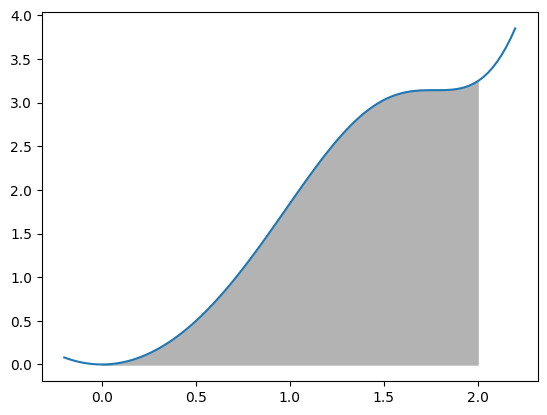

In [8]:
f = lambda x: np.sin(x**2)+x**2

x = np.linspace(-0.2, 2.2, 100)
y = f(x)

plt.plot(x,y)
z = np.linspace(0, 2, 100)
plt.fill_between(z, 0, f(z), color = "0.7")
plt.show()

https://www.wolframalpha.com/input?i=int_%7B0%7D%5E%7B2%7D+sin%28x%5E2%29%2Bx%5E2+dx

In [9]:
def pole(fun, a, b, n = 1000):
    P = 0
    for i in range(n):
        P+=fun(a+(b-a)*(i+1)/n)*((b-a)/n)
    return P

f = lambda x: np.sin(x**2)+x**2
print(pole(f, 0, 2))

3.4746868153222867


- Metoda Monte Carlo

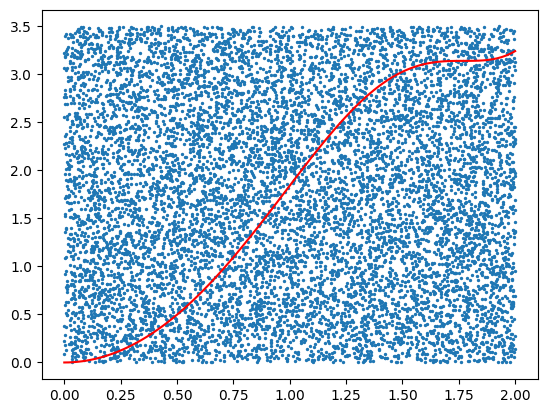

In [10]:
N = 10000
x1 = [r.uniform(0, 2) for i in range(N)]
y1 = [r.uniform(0, 3.5) for i in range(N)]


f = lambda x: np.sin(x**2)+x**2

x = np.linspace(0, 2, 100)
y = f(x)

plt.scatter(x1, y1, s =2)
plt.plot(x, y, c = "red")
plt.show()

In [11]:
ile = 0
for i in range(N):
    if y1[i] < f(x1[i]):
        ile+=1
print(ile)

4964


In [12]:
P = 2*3.5*ile/N
print(P)

3.4748


<h3> Centralne twierdzenie graniczne

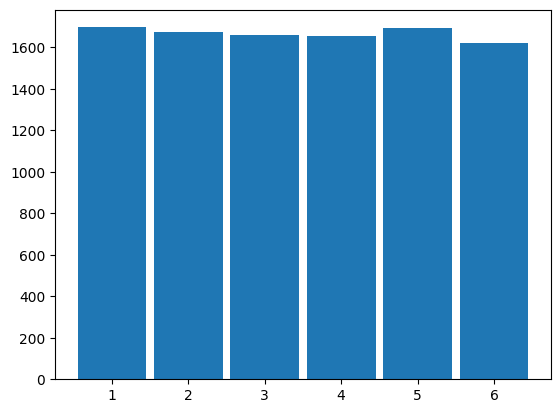

In [13]:
oczka = [1,2,3,4,5,6] #srednia=3.5

plt.hist(r.choices(oczka, k = 10000), rwidth=0.9, align='mid',bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5])
plt.show()

In [14]:
sum(r.choices(oczka, k = 10000))

34801

In [15]:
oczka = [1,2,3,4,5,6]
sumy = []
for i in range(1000):
    sumy.append(sum(r.choices(oczka, k = 10000)))

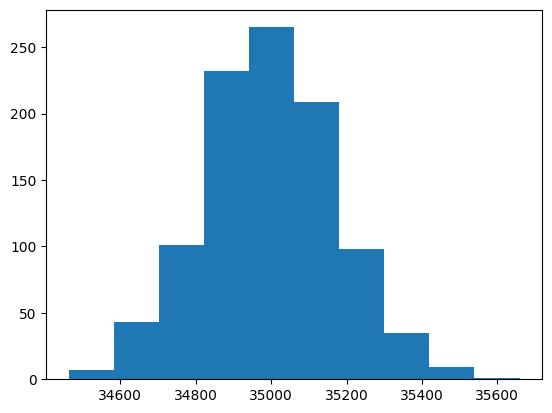

In [16]:
plt.hist(sumy, bins = 10)
plt.show()

W ogólności, przy pewnych założeniach (niezależność, ten sam rozkład, skończona wariancja): $X_1+X_2+...+X_n \sim N(n\mu, \sigma \sqrt{n})$

<h4> Zadanie1: W szklarni badacze analizują wysokość sadzonek pomidora po 30 dniach od posadzenia.

Wiadomo, że:
- wysokość sadzonek w całej populacji ma średnią ($\mu=18$) cm,
- odchylenie standardowe wynosi ($\sigma=4$) cm,
- losowo wybrano próbę ($n=64$) sadzonek.

Zakładamy, że obserwacje są niezależne.

Polecenia:
1. Korzystając z centralnego twierdzenia granicznego, określ rozkład średniej wysokości sadzonek w próbie.
2. Oblicz prawdopodobieństwo, że średnia wysokość sadzonek w próbie będzie większa niż 19 cm.
3. Oblicz prawdopodobieństwo, że średnia wysokość sadzonek znajdzie się między 17 a 19 cm.
4. Jak zmieni się błąd standardowy średniej, jeśli liczebność próby zwiększymy do 256 sadzonek?

In [2]:
#Co się może przydać?
from scipy.stats import norm 

print(norm.cdf(0)) #dystrybuanta rozkladu normalnego N(0,1) w pkt 0
print()
print(norm.cdf(171, loc =160, scale = 15)) #dystrybuanta rozkladu normalnego N(160,15) w pkt 171

0.5

0.7683224253652017


Ciekawostka: przy pewnych założeniach zachodzi CTW zachodzi dla zmiennych z różnych rozkładów.

Zastosowanie:
- geny w komórce, różne średnie poziomy ekspresji (i zmienności); suma ekspresji w przybliżeniu ma rozkład normalny

<h3> Twierdzenie Poissona

$\binom{n}{k}p^k(1-p)^{n-k} \rightarrow e^{-\lambda}\cdot \frac{\lambda^k}{k!}$, gdzie $\lambda \approx p\cdot n$.

In [17]:
from math import comb, e, factorial

#rozklad dwupunktowy
def Binom(p,n,k):
    return comb(n,k)*(p**k)*((1-p)**(n-k))

#rozklad Poissona
def Poisson(lam, k):
    return e**(-lam) * lam**k / factorial(k)

#Jeżeli p - małe, i p*n stała liczba (gdy liczymy granice), to przyjmując lambda = p*n rozklady dwupunktowe i Poissona sa zblizone
Binom(1/100, 100, 3), Poisson(1/100*100, 3)

(0.06099916580753064, 0.06131324019524039)

<h4> Zadanie2: Prawdopodobieństwo mutacji podczas mutacji wynosi $10^{-6}$. Rozważamy sekwencję DNA o długości $10^6$. Jakie jest prawdopodobieństwo, że w tym fragmencie wystąpią dokładnie 2 mutacje